In [1]:
#claudio-i@ace.me

In [1]:

import numpy as np
import pandas as pd
from scipy.io import loadmat
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import savgol_filter
import matplotlib.ticker as mticker
from multitaper import MTSpec

In [2]:
pwd

'/home/cl/Google/@doctorado-sync/codes/adcp-l1'

In [3]:
cd '/home/cl/Google/@doctorado-sync/codes'

/home/cl/Google/@doctorado-sync/codes


In [4]:
import numpy as np

def pca_time_depth(X):
    """
    X: array (ntime, ndepth). Returns PCs, EOFs, variance fraction.
    - Demeans each depth column.
    - Fills NaNs with 0 after demeaning (i.e., column mean).
    - Uses SVD on anomalies.
    """
    X = np.asarray(X, dtype=float)
    ntime, ndepth = X.shape

    # anomalies (demean columns)
    col_mean = np.nanmean(X, axis=0)
    Xa = X - col_mean

    # fill NaNs with 0 (column mean after demeaning)
    Xa = np.where(np.isnan(Xa), 0.0, Xa)

    # SVD: Xa = U S V^T
    U, S, VT = np.linalg.svd(Xa, full_matrices=False)
    V = VT.T

    # PCs (time series) and EOFs (vertical modes)
    PCs = U @ np.diag(S)          # (ntime, r)
    EOFs = V                      # (ndepth, r)

    # variance explained
    total_var = np.sum(np.var(Xa, axis=0, ddof=1))
    mode_var = (S**2) / (ntime - 1)
    var_frac = mode_var / total_var           # fraction per mode
    var_pct = 100 * var_frac

    return PCs, EOFs, var_frac, var_pct

In [5]:
import pickle

with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataA_h.pkl', 'rb') as f:
    dataA = pickle.load(f)

In [6]:
dataA['time'][0],dataA['time'][-1]

(Timestamp('2004-12-30 17:00:00'), Timestamp('2005-01-26 12:00:00'))

In [7]:
u_PCs, u_EOFs, u_var_frac, u_var_pct = pca_time_depth(dataA['u'][:,0:22])
v_PCs, v_EOFs, v_var_frac, v_var_pct = pca_time_depth(dataA['v'][:,0:22])

for i, p in enumerate(u_var_pct[:5], start=1):
    print(f"Mode-U {i}: {p:.2f}%")
for i, p in enumerate(v_var_pct[:5], start=1):
    print(f"Mode-V {i}: {p:.2f}%")

Mode-U 1: 35.89%
Mode-U 2: 29.59%
Mode-U 3: 14.43%
Mode-U 4: 8.34%
Mode-U 5: 4.65%
Mode-V 1: 47.37%
Mode-V 2: 21.12%
Mode-V 3: 14.73%
Mode-V 4: 8.13%
Mode-V 5: 2.92%


In [8]:
k = 10
X_recon = u_PCs[:, :k] @ u_EOFs[:, :k].T  # anomalies
X_recon += np.nanmean(dataA['u'][:,0:22], axis=0)
dataA['u_re'] = X_recon
del X_recon

k = 10
X_recon = v_PCs[:, :k] @ v_EOFs[:, :k].T  # anomalies
X_recon += np.nanmean(dataA['v'][:,0:22], axis=0)
dataA['v_re'] = X_recon
del X_recon

In [9]:
dataA['depth'] = dataA['depth'][0:22]

In [10]:
u_re1 = dataA['u_re']
v_re1 = dataA['v_re']
t1 = dataA['time']

In [11]:
#

In [12]:
from utide import solve, reconstruct

In [13]:
[u_re1.shape]

[(644, 22)]

In [14]:
u_re1_tide = np.full((644, 22), np.nan)
v_re1_tide = np.full((644, 22), np.nan)

for i1 in range(0,22):

    x = u_re1[:,i1]
    y = v_re1[:,i1]
    coef = solve(
        t1, x, y,
        lat=-36.4,
        nodal=False,
        trend=False,
        method='ols',
        conf_int='linear',
        Rayleigh_min=0.95,
        verbose=False
    );
    tide = reconstruct(t1, coef, verbose=False);

    u_re1_tide[:,i1] = tide['u']
    v_re1_tide[:,i1] = tide['v']

#---------------------------------

In [15]:
#

In [16]:
# DIURNAL EXTRACTION

Text(0.5, 1.0, '@Rec-Near-Diurnal')

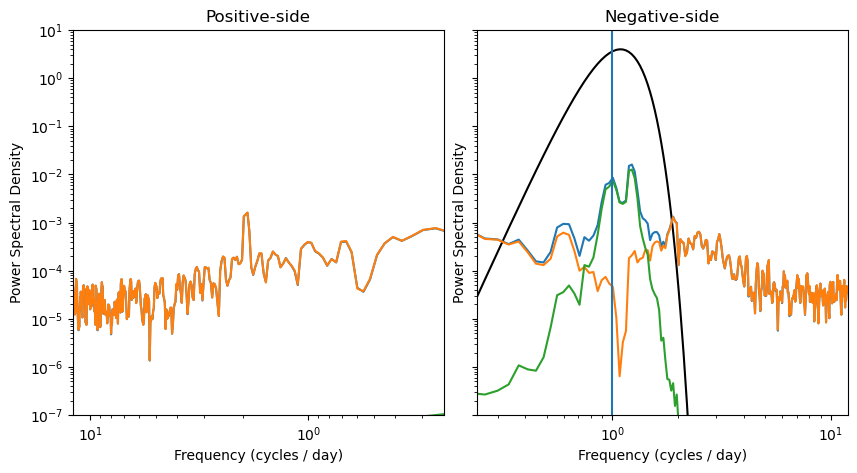

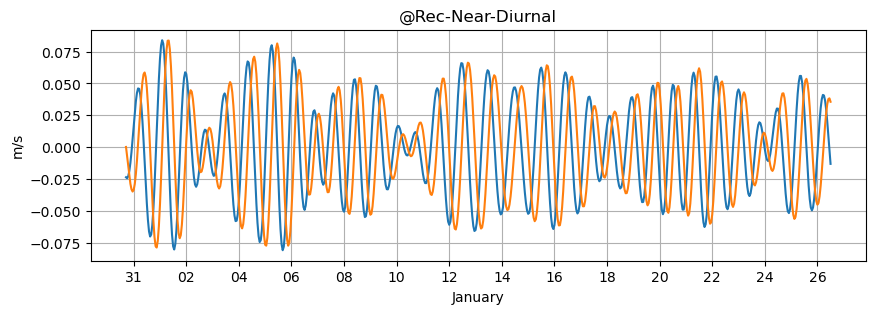

In [21]:
import clouddrift.wavelet as wt
from scipy import signal, ndimage

dt = 1/24
P = 2
x = u_re1[:,18]/1000
y = v_re1[:,18]/1000
cv = x + 1j * y
spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
S = np.ravel(spec.spec)
f = np.ravel(spec.freq)

gamma = 3
beta = 5
period = 22/24 #period you're interested in. Here it's the M2 tide,
omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

_, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
psif = psif[0,0]
cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
#cvo, _ = np.conj(wt.morse_wavelet_transform(np.conj(cv),gamma,beta,[omega],complex=True,boundary="mirror"))
cvr = cv - cvo

spec = MTSpec(cvo, nw=P, dt=dt, iadapt=1, nfft=len(cv))
So = np.ravel(spec.spec)

spec = MTSpec(cvr, nw=P, dt=dt, iadapt=1, nfft=len(cv))
Sr = np.ravel(spec.spec)

fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharey=True, gridspec_kw={"wspace": 0.09})

ax[0].loglog(-f[f<0],S[f<0])#plot negative side
ax[0].loglog(-f[f<0],Sr[f<0])#plot negative side
ax[0].loglog(-f[f<0],So[f<0])#plot negative side

ax[0].set_xlabel("Frequency (cycles / day)")
ax[0].set_ylabel("Power Spectral Density")
ax[0].set_xlim(np.max(f)/50, np.max(f))
ax[0].set_ylim(10e-8, 10e0)
ax[0].invert_xaxis()
ax[0].set_title("Positive-side")

ax[1].loglog(f[f>0], 1*np.abs(psif[f>0])**2, color="black")
ax[1].loglog(f[f>0],S[f>0])#plot positive side
ax[1].loglog(f[f>0],Sr[f>0])#plot positive side
ax[1].loglog(f[f>0],So[f>0])#plot positive side

ax[1].set_xlabel("Frequency (cycles / day)")
ax[1].set_ylabel("Power Spectral Density")
ax[1].set_xlim(np.max(f)/50, np.max(f))
ax[1].set_ylim(10e-8, 10e0)
ax[1].set_title("Negative-side")
ax[1].axvline(1)

#------------

plt.figure(figsize=(10,3))
plt.plot(t1,cvo.real)
plt.plot(t1,cvo.imag)
plt.grid()
plt.ylabel('m/s')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel(dataA['time'][50].strftime('%B'))
plt.title('@Rec-Near-Diurnal')

In [47]:
#

In [31]:
u_re1_diurnal = np.full((644, 22), np.nan)
v_re1_diurnal = np.full((644, 22), np.nan)

for i in range(0,22):

    dt = 1/24
    P = 2
    x = u_re1[:,i]/1000
    y = v_re1[:,i]/1000
    cv = x + 1j * y
    spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    S = np.ravel(spec.spec)
    f = np.ravel(spec.freq)

    gamma = 3
    beta = 5
    period = 22/24 #period you're interested in. Here it's the M2 tide,
    omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

    _, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
    psif = psif[0,0]
    cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
    u_re1_diurnal[:,i] = cvo.real
    v_re1_diurnal[:,i] = cvo.imag

#-----------------------------------------------------------------

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt, welch


def evaluate_5day_fluctuation(
    time_index, signal, fs_per_day=24.0, band_days=(4.0, 6.0)
):
    """Evaluates whether an hourly time-series signal has a significant ~5-day fluctuation.

    Parameters
    ----------
    time_index : pd.DatetimeIndex or array-like
        Time stamps of the hourly data.
    signal : array-like
        Hourly signal 1D array.
    fs_per_day : float
        Sampling frequency in cycles per day (24.0 for hourly data).
    band_days : tuple
        (min_days, max_days) period band to evaluate (default: 4.0 to 6.0 days).

    Returns
    -------
    dict : Dictionary containing significance flag, variance explained, and figures.
    """
    # 1. Clean & Detrend Signal
    signal = np.array(signal, dtype=float)
    if np.isnan(signal).any():
        signal = (
            pd.Series(signal).interpolate(method="linear").bfill().ffill().values
        )

    signal_detrended = signal - np.mean(signal)
    total_var = np.var(signal_detrended)

    # 2. Bandpass Filter (4 to 6 days)
    # Frequency bounds in cycles per day (cpd)
    f_low = 1.0 / band_days[1]  # 1/6 cpd = 0.167 cpd
    f_high = 1.0 / band_days[0]  # 1/4 cpd = 0.250 cpd
    f_nyquist = fs_per_day / 2.0  # 12.0 cpd for hourly data

    # Normalize frequencies by Nyquist
    low_norm = f_low / f_nyquist
    high_norm = f_high / f_nyquist

    b, a = butter(2, [low_norm, high_norm], btype="bandpass")
    signal_5day = filtfilt(b, a, signal_detrended)

    # Variance explained by the 5-day band
    var_5day = np.var(signal_5day)
    pct_var_explained = (var_5day / total_var) * 100.0 if total_var > 0 else 0.0

    # 3. Power Spectral Density (Welch's PSD)
    # nperseg set to 15 days (360 hours) to resolve low frequencies
    nperseg = min(len(signal), 360)
    freqs_cpd, psd = welch(
        signal_detrended, fs=fs_per_day, nperseg=nperseg, scaling="density"
    )

    # Spectral Peak in the 5-day band vs Background Noise
    mask_5day = (freqs_cpd >= f_low) & (freqs_cpd <= f_high)
    peak_psd_5day = (
        np.max(psd[mask_5day]) if np.any(mask_5day) else 0.0
    )
    mean_background_psd = np.mean(psd)
    snr_ratio = peak_psd_5day / mean_background_psd if mean_background_psd > 0 else 0.0

    # Decision threshold: Significant if 5-day band explains > 5% of variance
    # OR spectral peak in band is > 3x the average background spectrum
    is_significant = (pct_var_explained >= 5.0) or (snr_ratio >= 3.0)

    # 4. Diagnostic Figure Construction
    fig, axes = plt.subplots(
        2, 1, figsize=(10, 6.5), gridspec_kw={"height_ratios": [1, 1]}
    )

    # Panel A: Time Series Comparison
    axes[0].plot(
        time_index,
        signal_detrended,
        color="gray",
        alpha=0.55,
        linewidth=0.8,
        label="Detrended Signal",
    )
    axes[0].plot(
        time_index,
        signal_5day,
        color="crimson",
        linewidth=2.0,
        label=f"5-Day Filtered ({pct_var_explained:.1f}% Variance)",
    )
    axes[0].set_ylabel("Amplitude")
    axes[0].set_title(
        f"a) Time Domain Analysis (5-Day Fluctuation Significant: {is_significant})",
        loc="left",
        fontweight="bold",
    )
    axes[0].grid(True, linestyle=":", alpha=0.6)
    axes[0].legend(loc="upper right", frameon=True, facecolor="white")

    # Panel B: Power Spectral Density
    axes[1].semilogy(
        freqs_cpd, psd, color="navy", linewidth=1.2, label="Power Spectrum (PSD)"
    )
    axes[1].axvspan(
        f_low,
        f_high,
        color="gold",
        alpha=0.3,
        label=f"5-Day Band ({f_low:.2f}–{f_high:.2f} cpd)",
    )
    axes[1].axvline(
        0.2,
        color="crimson",
        linestyle="--",
        linewidth=1.2,
        label="5-Day Target (0.20 cpd)",
    )
    axes[1].set_xlabel("Frequency (cycles per day, cpd)")
    axes[1].set_ylabel(r"PSD ($\mathrm{Amplitude}^2 / \mathrm{cpd}$)")
    axes[1].set_xlim([0, 2.5])  # Focus on sub-diurnal / diurnal range
    axes[1].set_title(
        "b) Power Spectral Density & Target Frequency Peak",
        loc="left",
        fontweight="bold",
    )
    axes[1].grid(True, which="both", linestyle=":", alpha=0.6)
    axes[1].legend(loc="upper right", frameon=True, facecolor="white")

    plt.tight_layout()

    # Print Summary to Console
    print("=== 5-DAY FLUCTUATION EVALUATION ===")
    print(f"Total Signal Variance     : {total_var:.5f}")
    print(f"5-Day Band Variance       : {var_5day:.5f}")

=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00018
5-Day Band Variance       : 0.00001


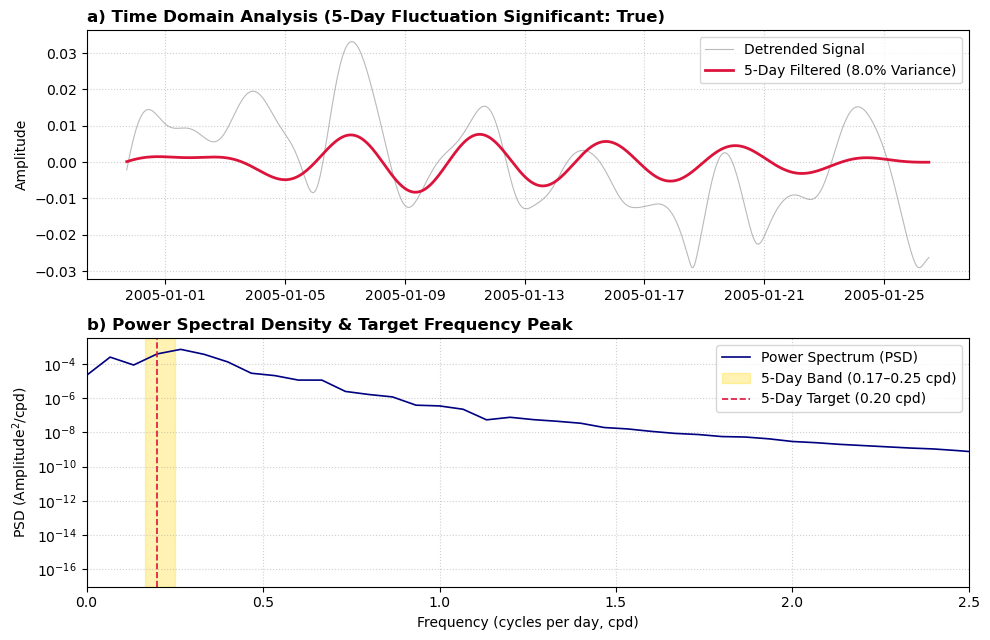

In [30]:
# Generate synthetic hourly data (e.g., January 2005 dataset)
times = dataA['time']
t_days = (times - times[0]).total_seconds() / 86400.0


# Evaluate signal
i = 1
x = np.sqrt(u_re1_diurnal[:,i]**2 + v_re1_diurnal[:,i]**2)
results = evaluate_5day_fluctuation(
    time_index=times, signal=x, fs_per_day=24.0
)

plt.show()

=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00013
5-Day Band Variance       : 0.00001
=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00018
5-Day Band Variance       : 0.00001
=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00021
5-Day Band Variance       : 0.00001
=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00022
5-Day Band Variance       : 0.00002
=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00022
5-Day Band Variance       : 0.00003
=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00022
5-Day Band Variance       : 0.00004
=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00019
5-Day Band Variance       : 0.00003
=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00016
5-Day Band Variance       : 0.00002
=== 5-DAY FLUCTUATION EVALUATION ===
Total Signal Variance     : 0.00015
5-Day Band Variance       : 0.00001
=== 5-DAY FLUCTUATI

/tmp/ipykernel_472794/544714380.py:74: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(


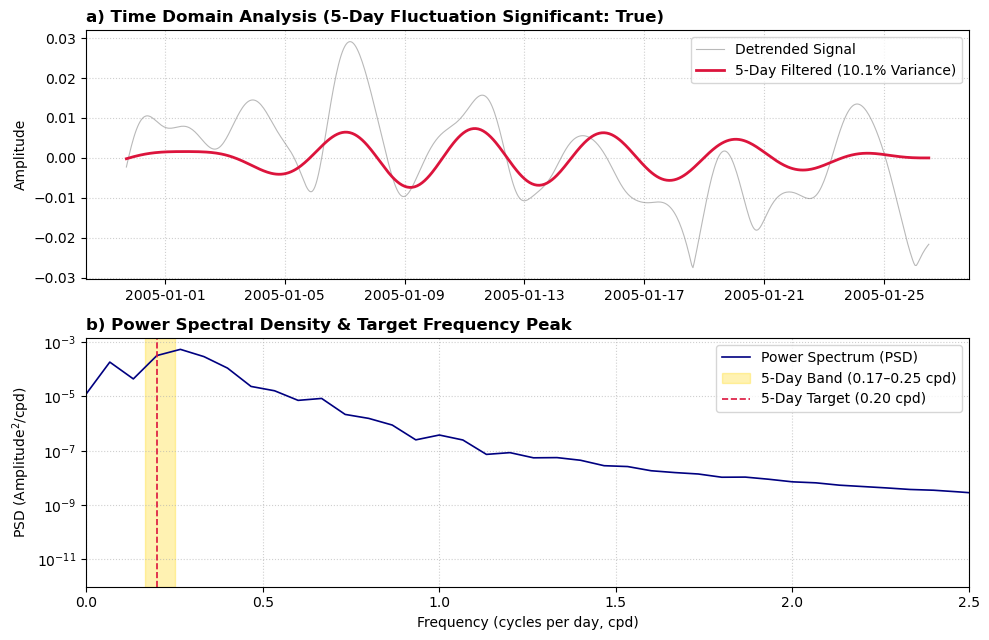

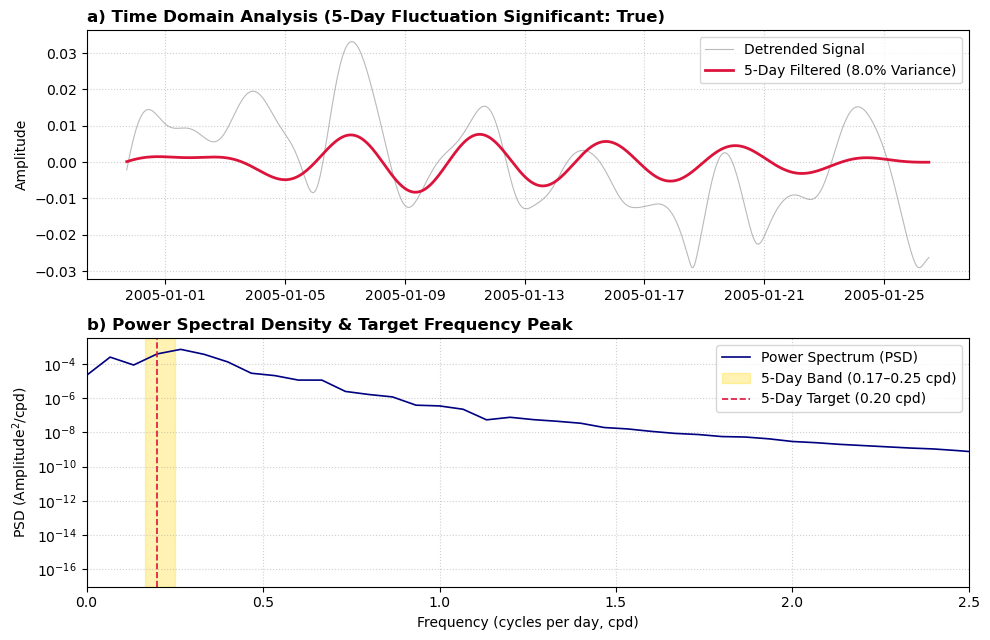

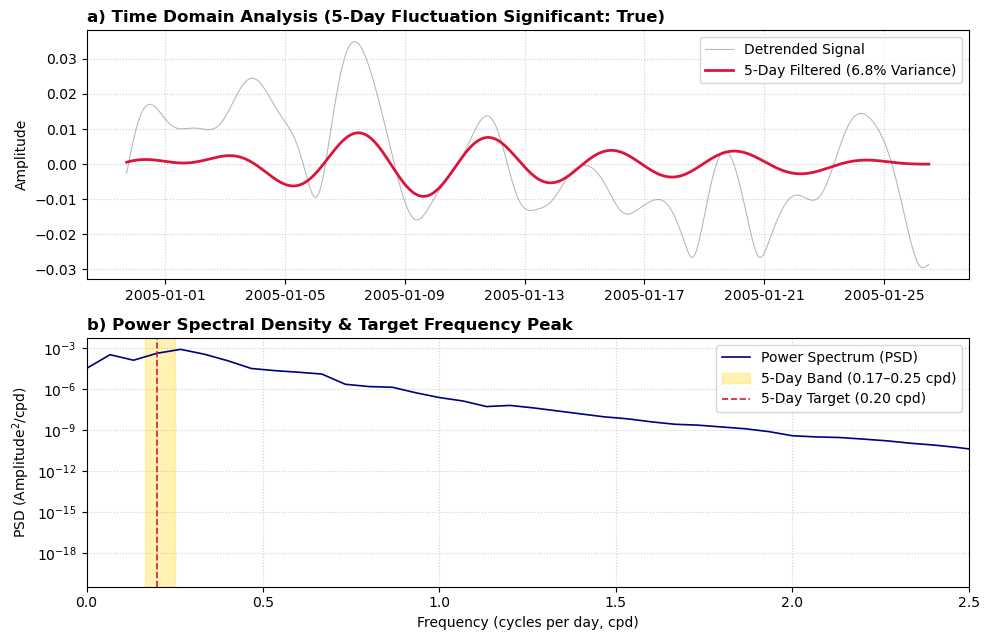

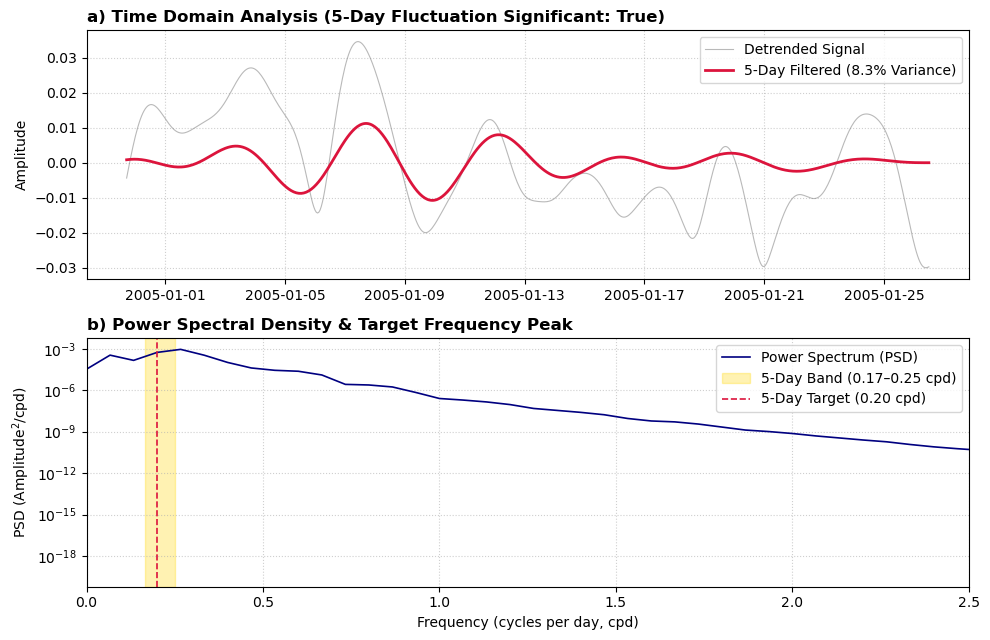

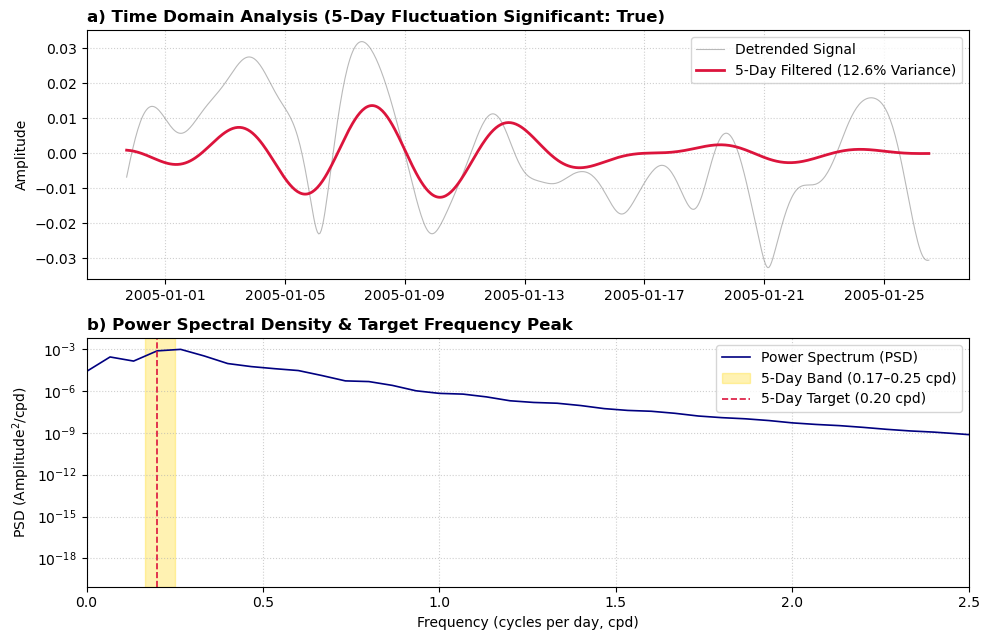

...

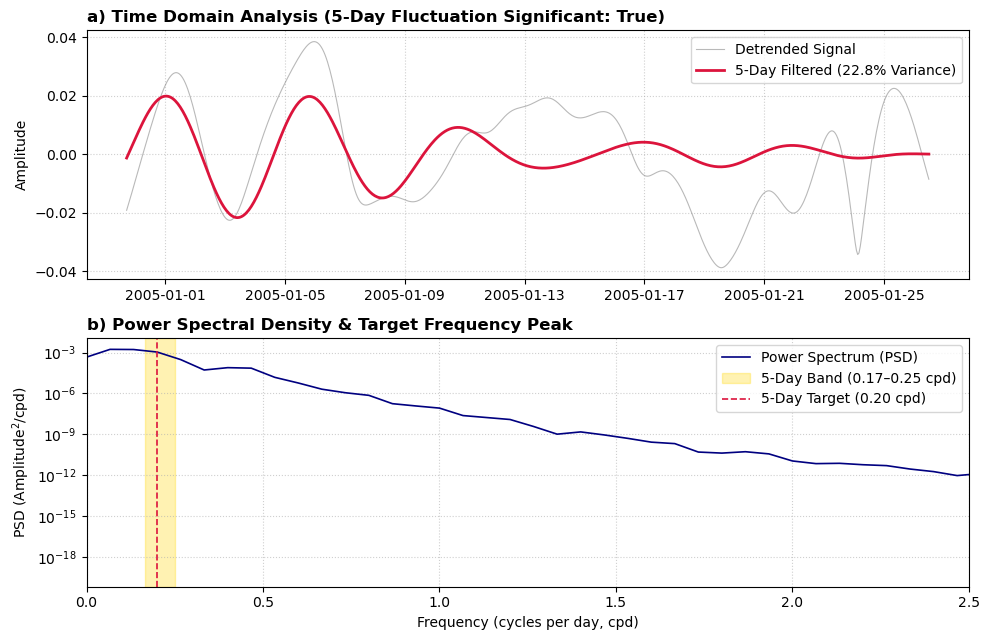

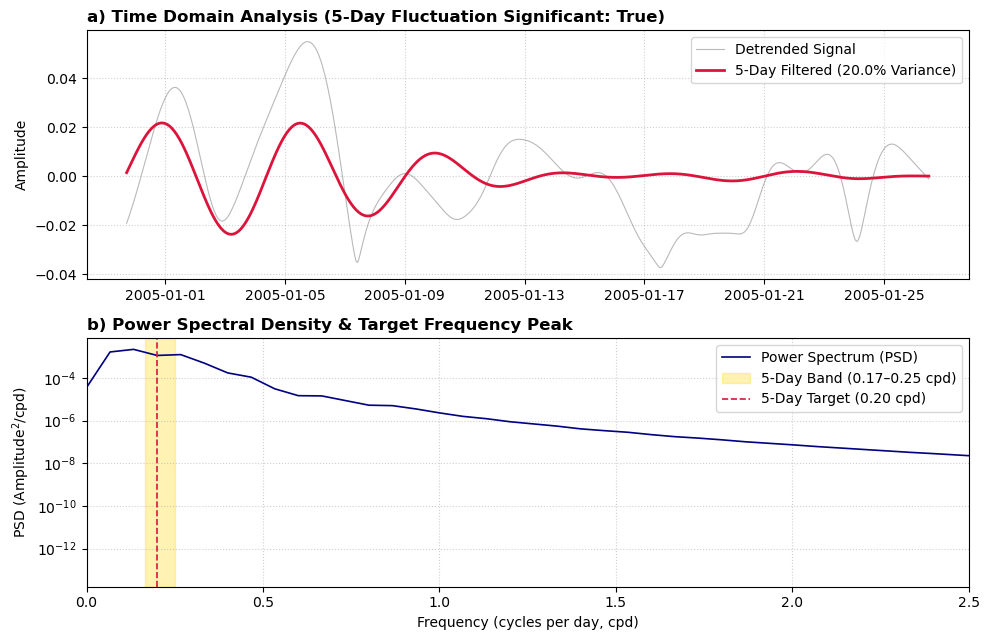

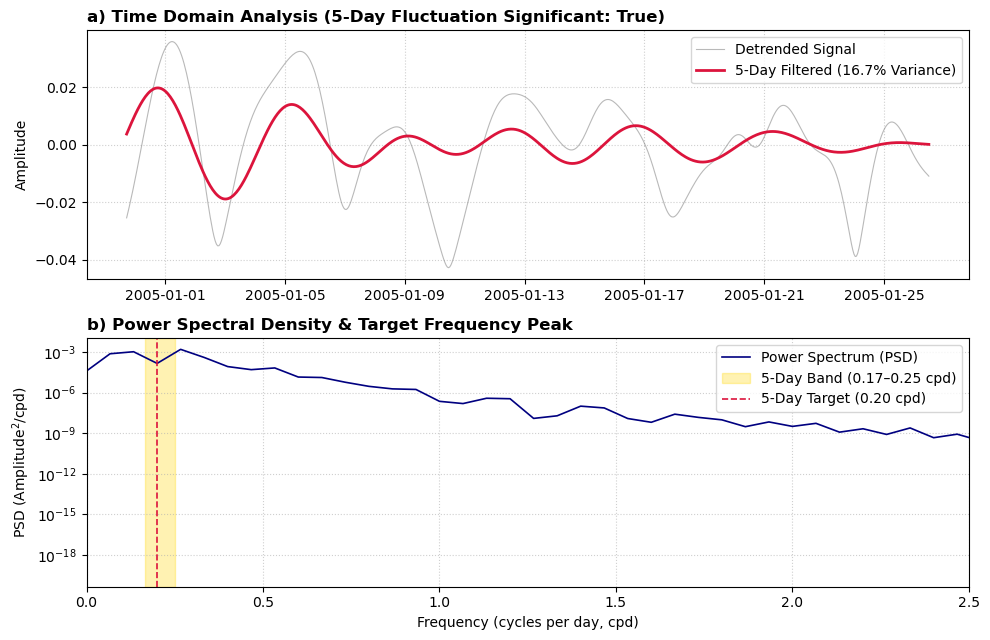

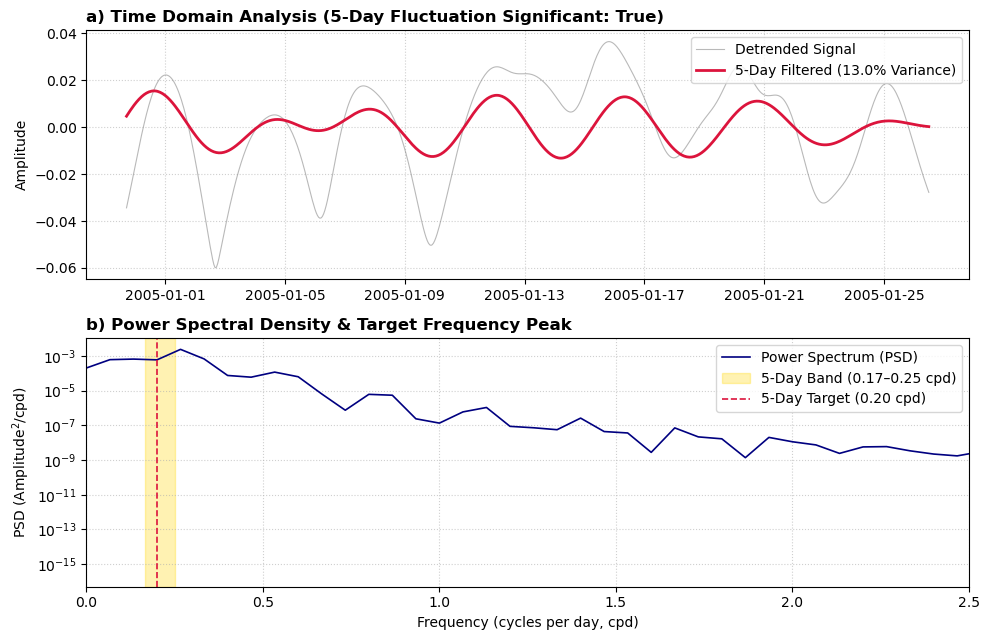

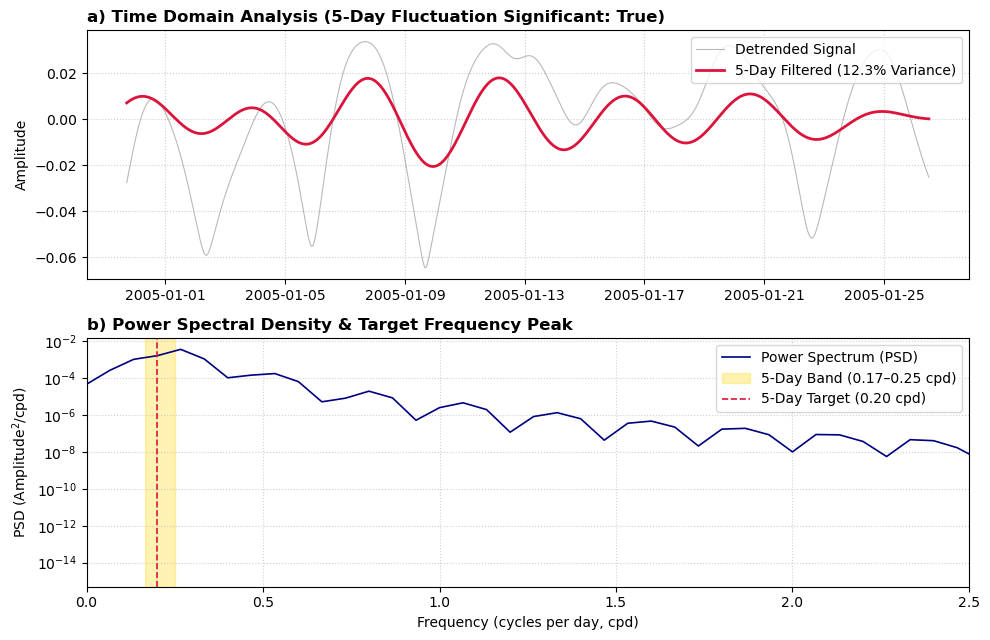

In [33]:
for i in range(0,21):
    x = np.sqrt(u_re1_diurnal[:,i]**2 + v_re1_diurnal[:,i]**2)
    results = evaluate_5day_fluctuation(time_index=times, signal=x, fs_per_day=24.0)

In [49]:
# INERTIAL EXTRACTION

Text(0.5, 1.0, '@Rec-Near-Inertial')

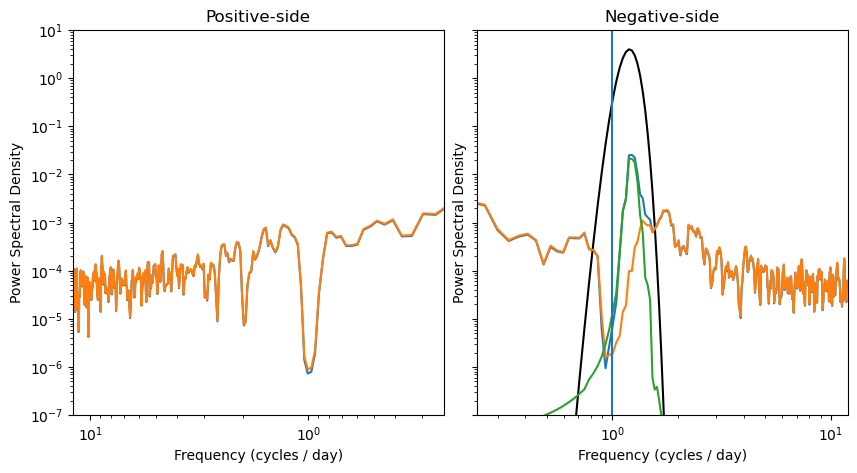

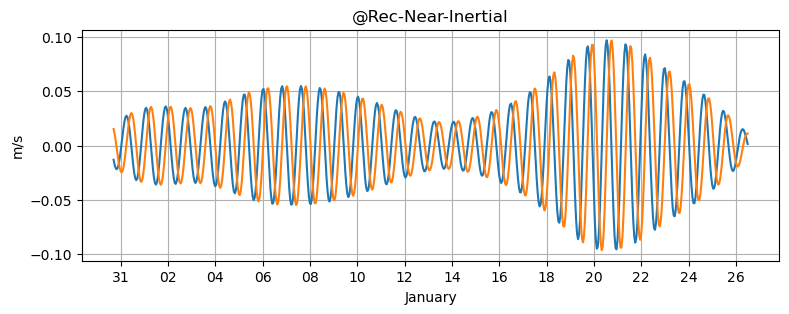

In [34]:
import clouddrift.wavelet as wt
from scipy import signal, ndimage

dt = 1/24
P = 2
x = u_re1[:,20]/1000 - u_re1_tide[:,20]/1000
y = v_re1[:,20]/1000 - v_re1_tide[:,20]/1000
cv = x + 1j * y
spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
S = np.ravel(spec.spec)
f = np.ravel(spec.freq)

gamma = 3
beta = 30
period = 20/24 #period you're interested in. Here it's the M2 tide,
omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

_, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
psif = psif[0,0]
cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
#cvo, _ = np.conj(wt.morse_wavelet_transform(np.conj(cv),gamma,beta,[omega],complex=True,boundary="mirror"))
cvr = cv - cvo

spec = MTSpec(cvo, nw=P, dt=dt, iadapt=1, nfft=len(cv))
So = np.ravel(spec.spec)

spec = MTSpec(cvr, nw=P, dt=dt, iadapt=1, nfft=len(cv))
Sr = np.ravel(spec.spec)

fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharey=True, gridspec_kw={"wspace": 0.09})

ax[0].loglog(-f[f<0],S[f<0])#plot negative side
ax[0].loglog(-f[f<0],Sr[f<0])#plot negative side
ax[0].loglog(-f[f<0],So[f<0])#plot negative side

ax[0].set_xlabel("Frequency (cycles / day)")
ax[0].set_ylabel("Power Spectral Density")
ax[0].set_xlim(np.max(f)/50, np.max(f))
ax[0].set_ylim(10e-8, 10e0)
ax[0].invert_xaxis()
ax[0].set_title("Positive-side")

ax[1].loglog(f[f>0], 1*np.abs(psif[f>0])**2, color="black")
ax[1].loglog(f[f>0],S[f>0])#plot positive side
ax[1].loglog(f[f>0],Sr[f>0])#plot positive side
ax[1].loglog(f[f>0],So[f>0])#plot positive side

ax[1].set_xlabel("Frequency (cycles / day)")
ax[1].set_ylabel("Power Spectral Density")
ax[1].set_xlim(np.max(f)/50, np.max(f))
ax[1].set_ylim(10e-8, 10e0)
ax[1].set_title("Negative-side")
ax[1].axvline(1)

#------------

plt.figure(figsize=(9,3))
plt.plot(t1,cvo.real)
plt.plot(t1,cvo.imag)
plt.grid()
plt.ylabel('m/s')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel(dataA['time'][50].strftime('%B'))
plt.title('@Rec-Near-Inertial')

In [35]:
u_re1_nios = np.full((644, 22), np.nan)
v_re1_nios = np.full((644, 22), np.nan)

for i in range(0,22):

    dt = 1/24
    P = 2
    x = u_re1[:,i]/1000- u_re1_tide[:,i]/1000
    y = v_re1[:,i]/1000- v_re1_tide[:,i]/1000
    cv = x + 1j * y
    spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    S = np.ravel(spec.spec)
    f = np.ravel(spec.freq)

    gamma = 3
    beta = 30
    period = 20/24 #period you're interested in. Here it's the M2 tide,
    omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

    _, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
    psif = psif[0,0]
    cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
    u_re1_nios[:,i] = cvo.real
    v_re1_nios[:,i] = cvo.imag

#-----------------------------------------------------------------


In [36]:
dataA['depth']-98

array([-91.96000004, -87.96000004, -83.96000004, -79.96000004,
       -75.96000004, -71.96000004, -67.96000004, -63.96000004,
       -59.96000004, -55.96000004, -51.96000004, -47.96000004,
       -43.96000004, -39.96000004, -35.96000004, -31.96000004,
       -27.96000004, -23.96000004, -19.96000004, -15.96000004,
       -11.96000004,  -7.96000004])

=== STATISTICAL SUMMARY OF NEAR-INERTIAL MOTIONS (JANUARY 2005) ===
 Depth_mab (m)  Depth_surface (m)  Mean_Speed (m/s)  Std_Speed (m/s)  Max_Speed (m/s)  P95_Speed (m/s)  Mean_NIKE (10^-4 m2/s2)  Max_NIKE (10^-4 m2/s2)
          6.04              93.96          0.019151         0.009457         0.041216         0.039300                 2.280922                8.493904
         10.04              89.96          0.023307         0.012154         0.051255         0.049036                 3.454740               13.135357
         14.04              85.96          0.026369         0.014432         0.058919         0.056435                 4.518106               17.357237
         18.04              81.96          0.027795         0.015243         0.061002         0.058645                 5.024490               18.606015
         22.04              77.96          0.027652         0.014554         0.057468         0.055416                 4.882187               16.512943
         26.04      

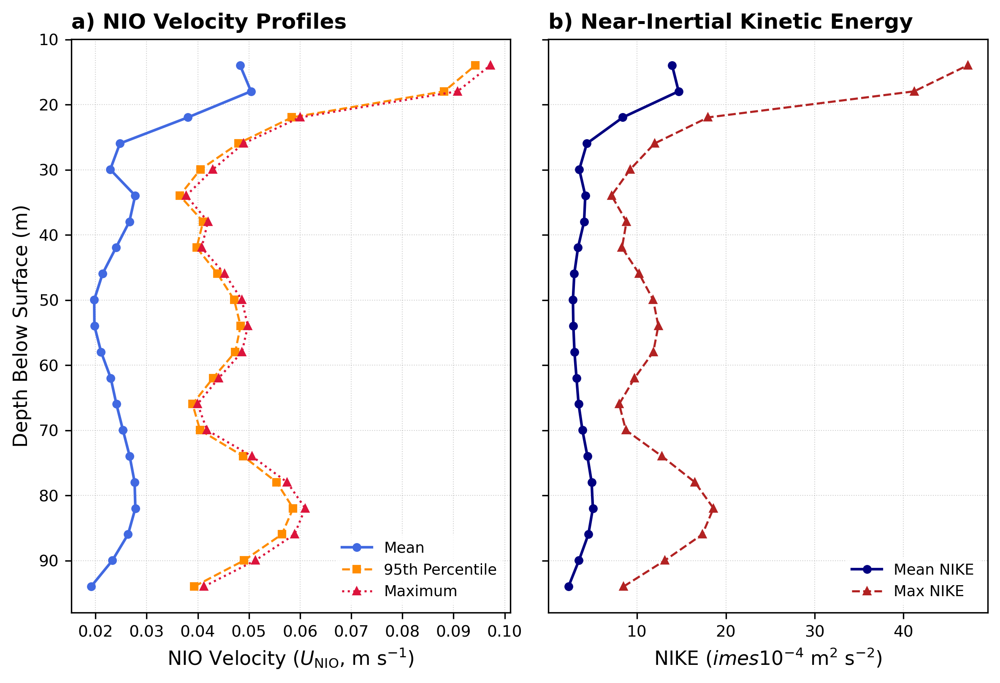

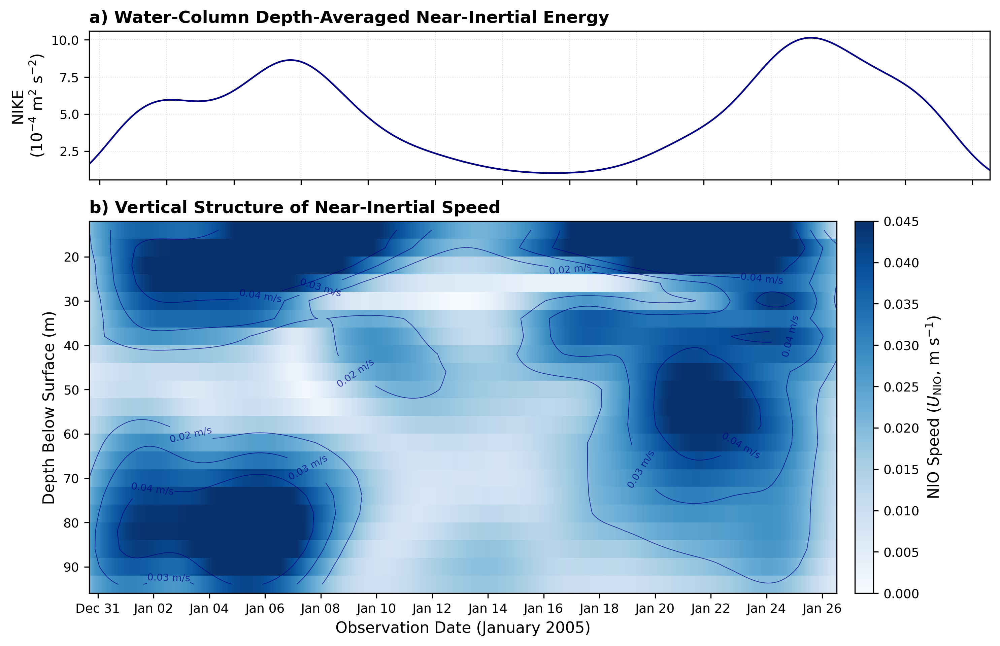

In [38]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. DEPTH CONVERSIONS & PHYSICAL METRICS
# ==========================================
# Depth in meters above bottom (mab) and meters below surface
depth_mab = np.array(dataA["depth"][0:21])  # 6.04 to 90.04 mab
depth_surface = 100.0 - depth_mab  # 93.96 to 9.96 m depth below surface
time_index = pd.to_datetime(dataA["time"])

# Near-Inertial Speed (m/s) and Specific Kinetic Energy (NIKE in m^2/s^2 or J/kg)
u_nio = u_re1_nios[:,0:21]  # shape (644, 22)
v_nio = v_re1_nios[:,0:21]  # shape (644, 22)

nio_speed = np.sqrt(u_nio**2 + v_nio**2)
nike = 0.5 * (u_nio**2 + v_nio**2)  # NIKE = 1/2 * (u^2 + v^2)

# Depth-averaged time series (water column integral proxy)
nike_depth_avg = np.mean(nike, axis=1)
speed_depth_avg = np.mean(nio_speed, axis=1)

# ==========================================
# 2. STATISTICAL SUMMARY TABLE
# ==========================================
df_nio_stats = pd.DataFrame(
    {
        "Depth_mab (m)": depth_mab,
        "Depth_surface (m)": depth_surface,
        "Mean_Speed (m/s)": np.mean(nio_speed, axis=0),
        "Std_Speed (m/s)": np.std(nio_speed, axis=0),
        "Max_Speed (m/s)": np.max(nio_speed, axis=0),
        "P95_Speed (m/s)": np.percentile(nio_speed, 95, axis=0),
        "Mean_NIKE (10^-4 m2/s2)": np.mean(nike, axis=0) * 1e4,
        "Max_NIKE (10^-4 m2/s2)": np.max(nike, axis=0) * 1e4,
    }
)

print("=== STATISTICAL SUMMARY OF NEAR-INERTIAL MOTIONS (JANUARY 2005) ===")
print(df_nio_stats.to_string(index=False))

# Export options for manuscript integration
# df_nio_stats.to_csv('NIO_Statistics_January2005.csv', index=False)
# df_nio_stats.to_latex('NIO_Statistics_Table.tex', index=False, float_format="%.4f")

# ==========================================
# 3. BURST EVENT IDENTIFICATION
# ==========================================
# Find top 3 peak depth-averaged NIO energy events
peak_indices = (
    pd.Series(nike_depth_avg).rolling(24, center=True).mean().nlargest(3).index
)
print("\n=== TOP 3 WINDFORCED NIO BURST EVENTS ===")
for rank, idx in enumerate(peak_indices, 1):
    event_time = time_index[idx]
    peak_speed = speed_depth_avg[idx]
    peak_energy = nike_depth_avg[idx] * 1e4
    print(
        f"Event {rank}: {event_time.strftime('%Y-%m-%d %H:%M')} | "
        f"Depth-Avg Speed: {peak_speed:.3f} m/s | "
        f"Depth-Avg NIKE: {peak_energy:.3f} x 10^-4 m^2/s^2"
    )

# ==========================================
# 4. VISUALIZATION 1: VERTICAL PROFILES
# ==========================================
fig, ax = plt.subplots(1, 2, figsize=(8, 5.5), sharey=True)

# Panel A: NIO Velocity Profiles
ax[0].plot(
    df_nio_stats["Mean_Speed (m/s)"],
    depth_surface,
    "o-",
    color="royalblue",
    linewidth=1.5,
    markersize=4,
    label="Mean",
)
ax[0].plot(
    df_nio_stats["P95_Speed (m/s)"],
    depth_surface,
    "s--",
    color="darkorange",
    linewidth=1.2,
    markersize=4,
    label="95th Percentile",
)
ax[0].plot(
    df_nio_stats["Max_Speed (m/s)"],
    depth_surface,
    "^:",
    color="crimson",
    linewidth=1.2,
    markersize=4,
    label="Maximum",
)

ax[0].set_xlabel("NIO Velocity ($U_{\mathrm{NIO}}$, m s$^{-1}$)")
ax[0].set_ylabel("Depth Below Surface (m)")
ax[0].set_title("a) NIO Velocity Profiles", loc="left", fontweight="bold")
ax[0].grid(True, linestyle=":", alpha=0.6)
ax[0].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax[0].invert_yaxis()  # Surface at top

# Panel B: Specific Near-Inertial Kinetic Energy (NIKE)
ax[1].plot(
    df_nio_stats["Mean_NIKE (10^-4 m2/s2)"],
    depth_surface,
    "o-",
    color="navy",
    linewidth=1.5,
    markersize=4,
    label="Mean NIKE",
)
ax[1].plot(
    df_nio_stats["Max_NIKE (10^-4 m2/s2)"],
    depth_surface,
    "^--",
    color="firebrick",
    linewidth=1.2,
    markersize=4,
    label="Max NIKE",
)

ax[1].set_xlabel("NIKE ($\times 10^{-4}$ m$^{2}$ s$^{-2}$)")
ax[1].set_title("b) Near-Inertial Kinetic Energy", loc="left", fontweight="bold")
ax[1].grid(True, linestyle=":", alpha=0.6)
ax[1].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)

plt.tight_layout()
plt.show()

# ==========================================
# 5. VISUALIZATION 2: TIME-DEPTH HOVMÖLLER SECTION
# ==========================================
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 2.5]}
)

# Upper panel: Depth-Averaged NIKE Time Series
ax1.plot(
    time_index,
    nike_depth_avg * 1e4,
    color="navy",
    linewidth=1.2,
    label="Depth-Averaged NIKE",
)
ax1.set_ylabel("NIKE\n($10^{-4}$ m$^2$ s$^{-2}$)")
ax1.set_title(
    "a) Water-Column Depth-Averaged Near-Inertial Energy",
    loc="left",
    fontweight="bold",
)
ax1.grid(True, linestyle=":", alpha=0.5)

# Lower panel: Time-Depth Hovmöller Plot
T, Z = np.meshgrid(time_index, depth_surface)
pcm = ax2.pcolormesh(
    T, Z, nio_speed.T, cmap="Blues", shading="auto", vmin=0, vmax=0.045
)

# Add contour lines for peak events
contours = ax2.contour(
    T,
    Z,
    nio_speed.T,
    levels=[0.02, 0.03, 0.04],
    colors="navy",
    linewidths=0.5,
    alpha=0.7,
)
ax2.clabel(contours, inline=True, fontsize=7, fmt="%.2f m/s")

cbar = fig.colorbar(
    pcm, ax=ax2, pad=0.02, label="NIO Speed ($U_{\mathrm{NIO}}$, m s$^{-1}$)"
)
ax2.set_ylabel("Depth Below Surface (m)")
ax2.set_xlabel("Observation Date (January 2005)")
ax2.set_title(
    "b) Vertical Structure of Near-Inertial Speed", loc="left", fontweight="bold"
)
ax2.invert_yaxis()

ax2.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

=== NEAR-INERTIAL ORBITAL RADIUS STATISTICS (JANUARY 2005) ===
 Depth_mab (m)  Depth_surface (m)  Min_Radius (km)  Mean_Radius (km)  Max_Radius (km)  P95_Radius (km)  Mean_Radius (m)  Max_Radius (m)
          6.04              93.96         0.063958          0.219450         0.472304         0.450342       219.449681      472.303650
         10.04              89.96         0.083148          0.267084         0.587339         0.561908       267.084037      587.338635
         14.04              85.96         0.091324          0.302168         0.675162         0.646694       302.168285      675.161895
         18.04              81.96         0.087195          0.318506         0.699028         0.672017       318.506029      699.027570
         22.04              77.96         0.085589          0.316868         0.658537         0.635015       316.868436      658.536514
         26.04              73.96         0.084871          0.305780         0.579548         0.560079       305.779690  

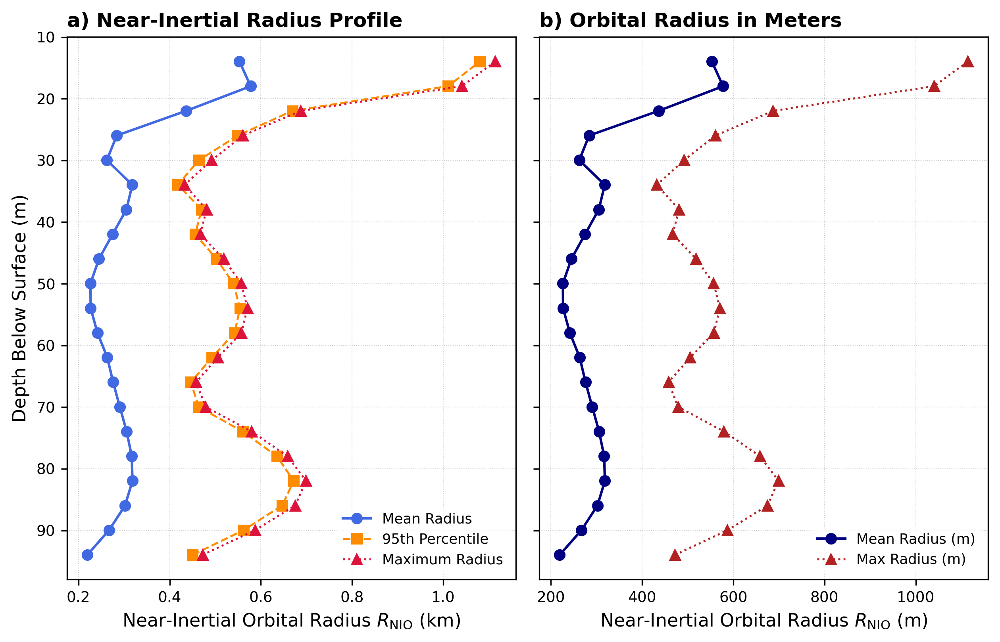

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# 1. PARAMETERS & RADIUS CALCULATION
# ==========================================
# Near-Inertial Period T = 20 hours for central Chile (~36.5°S)
T_nio_sec = 20.0 * 3600.0  # 72,000 seconds
omega_nio = (2.0 * np.pi) / T_nio_sec  # rad/s

# Depth levels (mab and surface depth)
depth_mab = np.array(dataA["depth"][0:21])  # 6.04 to 90.04 mab
depth_surface = 100.0 - depth_mab  # 93.96 to 9.96 m depth below surface

# Near-Inertial Speed U_NIO (m/s) from wavelets
u_nio = u_re1_nios[:,0:21]  # shape (644, 22)
v_nio = v_re1_nios[:,0:21]  # shape (644, 22)
nio_speed = np.sqrt(u_nio**2 + v_nio**2)  # m/s

# Orbital Radius R_NIO in kilometers
r_nio_km = (nio_speed / omega_nio) / 1000.0  # km
r_nio_m = r_nio_km * 1000.0  # meters for reference

# Cumulative progressive vector displacement in kilometers
dt_sec = 3600.0  # 1 hour timestep
x_disp_km = np.cumsum(u_nio * dt_sec, axis=0) / 1000.0  # km
y_disp_km = np.cumsum(v_nio * dt_sec, axis=0) / 1000.0  # km

# ==========================================
# 2. RADIUS STATISTICAL SUMMARY TABLE
# ==========================================
df_radius_stats = pd.DataFrame(
    {
        "Depth_mab (m)": depth_mab,
        "Depth_surface (m)": depth_surface,
        "Min_Radius (km)": np.min(r_nio_km, axis=0),
        "Mean_Radius (km)": np.mean(r_nio_km, axis=0),
        "Max_Radius (km)": np.max(r_nio_km, axis=0),
        "P95_Radius (km)": np.percentile(r_nio_km, 95, axis=0),
        "Mean_Radius (m)": np.mean(r_nio_m, axis=0),
        "Max_Radius (m)": np.max(r_nio_m, axis=0),
    }
)

print("=== NEAR-INERTIAL ORBITAL RADIUS STATISTICS (JANUARY 2005) ===")
print(df_radius_stats.to_string(index=False))

# Identify overall extreme radius events
min_r_overall = np.min(r_nio_km)
max_r_overall = np.max(r_nio_km)

min_loc = np.unravel_index(np.argmin(r_nio_km), r_nio_km.shape)
max_loc = np.unravel_index(np.argmax(r_nio_km), r_nio_km.shape)

time_index = pd.to_datetime(dataA["time"])

print("\n=== OVERALL EXTREME ORBITAL RADII ===")
print(
    f"SMALLEST ORBIT: {min_r_overall*1000:.2f} m ({min_r_overall:.4f} km) "
    f"at {depth_surface[min_loc[1]]:.1f}m depth on {time_index[min_loc[0]].strftime('%Y-%m-%d %H:%M')}"
)
print(
    f"LARGEST ORBIT:  {max_r_overall*1000:.2f} m ({max_r_overall:.4f} km) "
    f"at {depth_surface[max_loc[1]]:.1f}m depth on {time_index[max_loc[0]].strftime('%Y-%m-%d %H:%M')}"
)

# ==========================================
# 3. PUBLICATION FIGURE: ORBITAL RADIUS PROFILES & TRAJECTORIES
# ==========================================
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "figure.dpi": 300,
    }
)

fig, ax = plt.subplots(1, 2, figsize=(8.5, 5.5), sharey=True)

# Panel a: Radius in Kilometers Across Depth
ax[0].plot(
    df_radius_stats["Mean_Radius (km)"],
    depth_surface,
    "o-",
    color="royalblue",
    linewidth=1.5,
    label="Mean Radius",
)
ax[0].plot(
    df_radius_stats["P95_Radius (km)"],
    depth_surface,
    "s--",
    color="darkorange",
    linewidth=1.2,
    label="95th Percentile",
)
ax[0].plot(
    df_radius_stats["Max_Radius (km)"],
    depth_surface,
    "^:",
    color="crimson",
    linewidth=1.2,
    label="Maximum Radius",
)

ax[0].set_xlabel("Near-Inertial Orbital Radius $R_{\mathrm{NIO}}$ (km)")
ax[0].set_ylabel("Depth Below Surface (m)")
ax[0].set_title("a) Near-Inertial Radius Profile", loc="left", fontweight="bold")
ax[0].grid(True, linestyle=":", alpha=0.6)
ax[0].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax[0].invert_yaxis()

# Panel b: Radius in Meters Across Depth (Expanded scale)
ax[1].plot(
    df_radius_stats["Mean_Radius (m)"],
    depth_surface,
    "o-",
    color="navy",
    linewidth=1.5,
    label="Mean Radius (m)",
)
ax[1].plot(
    df_radius_stats["Max_Radius (m)"],
    depth_surface,
    "^:",
    color="firebrick",
    linewidth=1.2,
    label="Max Radius (m)",
)

ax[1].set_xlabel("Near-Inertial Orbital Radius $R_{\mathrm{NIO}}$ (m)")
ax[1].set_title(
    "b) Orbital Radius in Meters", loc="left", fontweight="bold"
)
ax[1].grid(True, linestyle=":", alpha=0.6)
ax[1].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)

plt.tight_layout()
plt.show()

=== DIURNAL DECAY ANALYSIS (JAN 07 - JAN 15 RELAXATION) ===
Initial Daily NIKE (E0): 5.263 x 10^-4 m^2/s^2
e-Folding Decay Timescale (tau): 3.56 days
Damping Rate (lambda): 0.281 day^-1
Daily Energy Loss Rate: 24.5% per day

=== DEPTH-DEPENDENT DECAY TIMESCALES ===
 Depth_mab (m)  Depth_surface (m)  eFolding_Tau (days)  Daily_Decay_Rate (%)
          6.04              93.96             6.987996             13.333480
         10.04              89.96             2.426643             33.773656
         14.04              85.96             1.088226             60.105319
         18.04              81.96             1.176299             57.263815
         22.04              77.96             1.331146             52.821524
         26.04              73.96             1.498174             48.699998
         30.04              69.96             1.687530             44.710211
         34.04              65.96             1.972992             39.760654
         38.04              61.96        

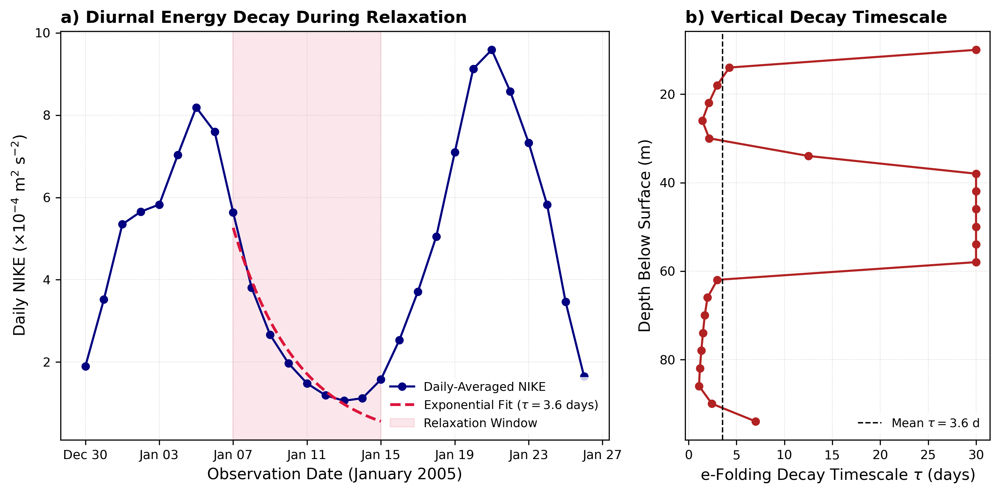

In [40]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. COMPUTE HOURLY METRICS & PANDAS DATAFRAME
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"])  # meters above bottom
depth_surface = 100.0 - depth_mab  # meters below surface

# Velocity magnitude (m/s) and Specific NIKE (m^2/s^2)
u_nio = u_re1_nios  # shape (644, 22)
v_nio = v_re1_nios  # shape (644, 22)

u_nio_speed = np.sqrt(u_nio**2 + v_nio**2)
nike_hourly = 0.5 * (u_nio**2 + v_nio**2)

# Build Pandas DataFrame for daily resampling
df_nike_hourly = pd.DataFrame(nike_hourly, index=time_index)
df_speed_hourly = pd.DataFrame(u_nio_speed, index=time_index)

# ==========================================
# 2. DIURNAL (DAILY) AVERAGING
# ==========================================
# Daily mean NIKE and Speed across all depths
df_nike_daily = df_nike_hourly.resample("D").mean()
df_speed_daily = df_speed_hourly.resample("D").mean()

daily_dates = df_nike_daily.index
nike_daily_array = df_nike_daily.values  # shape (n_days, 22)
speed_daily_array = df_speed_daily.values  # shape (n_days, 22)

# Water-column depth-averaged daily NIKE
nike_daily_depth_avg = np.mean(nike_daily_array, axis=1)

# ==========================================
# 3. EXPONENTIAL DECAY FIT FUNCTION
# ==========================================
def exp_decay(t, E0, tau):
    """Exponential decay model: E(t) = E0 * exp(-t / tau)"""
    return E0 * np.exp(-t / tau)


# Define wind-relaxation decay window (e.g., Post-Jan 07 burst: Jan 07 to Jan 15)
decay_start_date = "2005-01-07"
decay_end_date = "2005-01-15"

mask_decay = (daily_dates >= decay_start_date) & (daily_dates <= decay_end_date)
decay_dates = daily_dates[mask_decay]
t_days = (decay_dates - decay_dates[0]).days.values.astype(float)

# Fit for depth-averaged NIKE decay
y_decay_avg = nike_daily_depth_avg[mask_decay]
popt_avg, pcov_avg = curve_fit(
    exp_decay, t_days, y_decay_avg, p0=[y_decay_avg[0], 3.0]
)

E0_avg_fit, tau_avg_fit = popt_avg
lambda_avg = 1.0 / tau_avg_fit
daily_decay_rate_pct = (1.0 - np.exp(-lambda_avg)) * 100.0

print("=== DIURNAL DECAY ANALYSIS (JAN 07 - JAN 15 RELAXATION) ===")
print(f"Initial Daily NIKE (E0): {E0_avg_fit*1e4:.3f} x 10^-4 m^2/s^2")
print(f"e-Folding Decay Timescale (tau): {tau_avg_fit:.2f} days")
print(f"Damping Rate (lambda): {lambda_avg:.3f} day^-1")
print(f"Daily Energy Loss Rate: {daily_decay_rate_pct:.1f}% per day\n")

# ==========================================
# 4. DEPTH-DEPENDENT DECAY FIT
# ==========================================
tau_profile = []
daily_decay_pct_profile = []

for z_idx in range(len(depth_mab)):
    y_z = nike_daily_array[mask_decay, z_idx]
    try:
        popt_z, _ = curve_fit(
            exp_decay,
            t_days,
            y_z,
            p0=[y_z[0], 3.0],
            bounds=(0, [np.inf, 30.0]),
        )
        tau_z = popt_z[1]
    except RuntimeError:
        tau_z = np.nan

    rate_pct_z = (1.0 - np.exp(-1.0 / tau_z)) * 100.0 if not np.isnan(tau_z) else np.nan
    tau_profile.append(tau_z)
    daily_decay_pct_profile.append(rate_pct_z)

df_decay_stats = pd.DataFrame(
    {
        "Depth_mab (m)": depth_mab,
        "Depth_surface (m)": depth_surface,
        "eFolding_Tau (days)": tau_profile,
        "Daily_Decay_Rate (%)": daily_decay_pct_profile,
    }
)

print("=== DEPTH-DEPENDENT DECAY TIMESCALES ===")
print(df_decay_stats.to_string(index=False))

# ==========================================
# 5. PUBLICATION VISUALIZATION (CORRECTED)
# ==========================================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 5), gridspec_kw={"width_ratios": [1.8, 1]}
)

# Panel A: Daily NIKE Time Series & Fitted Exponential Decay
ax1.plot(
    daily_dates,
    nike_daily_depth_avg * 1e4,
    "o-",
    color="navy",
    linewidth=1.5,
    markersize=5,
    label="Daily-Averaged NIKE",
)

# Plot Exponential Fit Curve (Fixed raw string for TeX formatting)
t_fine = np.linspace(0, t_days[-1], 100)
fit_dates = [decay_dates[0] + pd.Timedelta(days=t) for t in t_fine]
fit_nike = exp_decay(t_fine, E0_avg_fit, tau_avg_fit) * 1e4

ax1.plot(
    fit_dates,
    fit_nike,
    "--",
    color="crimson",
    linewidth=2.0,
    label=rf"Exponential Fit ($\tau = {tau_avg_fit:.1f}$ days)",
)

ax1.axvspan(
    decay_dates[0],
    decay_dates[-1],
    color="crimson",
    alpha=0.1,
    label="Relaxation Window",
)

ax1.set_ylabel(r"Daily NIKE ($\times 10^{-4}$ m$^2$ s$^{-2}$)")
ax1.set_xlabel("Observation Date (January 2005)")
ax1.set_title(
    "a) Diurnal Energy Decay During Relaxation", loc="left", fontweight="bold"
)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

# Panel B: Vertical Profile of e-Folding Decay Timescale (tau)
ax2.plot(
    tau_profile,
    depth_surface,
    "o-",
    color="firebrick",
    linewidth=1.5,
    markersize=5,
)
ax2.axvline(
    tau_avg_fit,
    linestyle="--",
    color="black",
    linewidth=1.0,
    label=rf"Mean $\tau = {tau_avg_fit:.1f}$ d",
)

ax2.set_xlabel(r"e-Folding Decay Timescale $\tau$ (days)")
ax2.set_ylabel("Depth Below Surface (m)")
ax2.set_title("b) Vertical Decay Timescale", loc="left", fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

=== SEPARATE U and V NIO DECAY ANALYSIS (JAN 07 - JAN 15) ===
u_NIO (Zonal): A0 = 0.0255 m/s | tau_u = 10.53 d | Daily Loss = 9.1%/day
v_NIO (Meridional): A0 = 0.0255 m/s | tau_v = 10.53 d | Daily Loss = 9.1%/day

=== DEPTH-DEPENDENT TIMESCALES (TAU_U vs TAU_V) ===
 Depth_mab (m)  Depth_surface (m)  Tau_u (days)  Tau_v (days)
          6.04              93.96      0.048619      0.048609
         10.04              89.96      0.041759      0.041741
         14.04              85.96      0.033424      0.033410
         18.04              81.96      0.024748      0.024737
         22.04              77.96      0.017433      0.017424
         26.04              73.96      0.012726      0.012719
         30.04              69.96      0.010062      0.010057
         34.04              65.96      0.007570      0.007567
         38.04              61.96      0.005182      0.005184
         42.04              57.96     30.000000     30.000000
         46.04              53.96     30.000000     

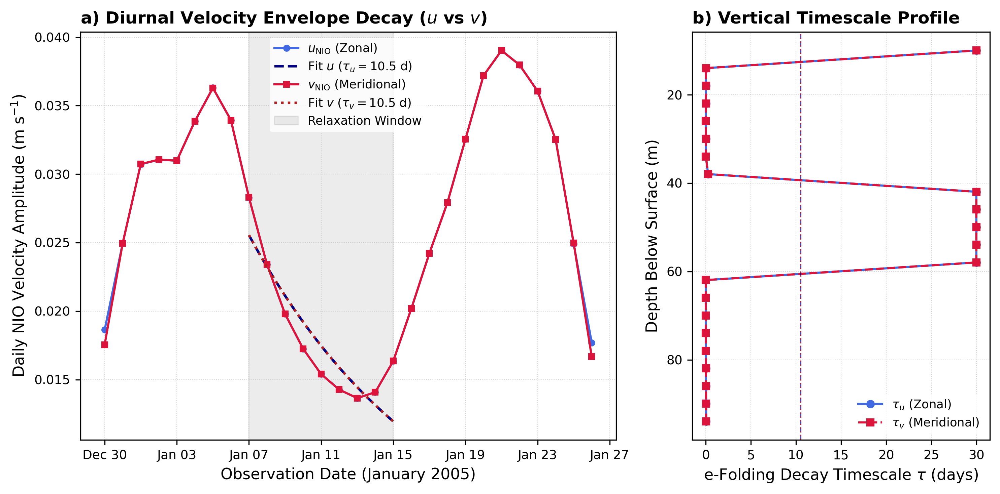

In [41]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from scipy.signal import hilbert

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. EXTRACT INSTANTANEOUS AMPLITUDE ENVELOPES (HILBERT TRANSFORM)
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"])  # meters above bottom
depth_surface = 100.0 - depth_mab  # meters below surface

u_nio = u_re1_nios  # shape (644, 22)
v_nio = v_re1_nios  # shape (644, 22)

# Compute Hilbert transform envelopes across all depth channels
env_u_hourly = np.abs(hilbert(u_nio, axis=0))  # m/s
env_v_hourly = np.abs(hilbert(v_nio, axis=0))  # m/s

# Build Pandas DataFrames for daily resampling
df_env_u = pd.DataFrame(env_u_hourly, index=time_index)
df_env_v = pd.DataFrame(env_v_hourly, index=time_index)

# ==========================================
# 2. DIURNAL (DAILY) AVERAGING
# ==========================================
df_u_daily = df_env_u.resample("D").mean()
df_v_daily = df_env_v.resample("D").mean()

daily_dates = df_u_daily.index
u_daily_array = df_u_daily.values  # shape (n_days, 22)
v_daily_array = df_v_daily.values  # shape (n_days, 22)

# Water-column depth-averaged daily amplitudes
u_daily_depth_avg = np.mean(u_daily_array, axis=1)
v_daily_depth_avg = np.mean(v_daily_array, axis=1)

# ==========================================
# 3. EXPONENTIAL DECAY FITTING
# ==========================================
def exp_decay(t, A0, tau):
    """Exponential decay function: A(t) = A0 * exp(-t / tau)"""
    return A0 * np.exp(-t / tau)


# Define post-forcing relaxation window (Jan 07 - Jan 15)
decay_start_date = "2005-01-07"
decay_end_date = "2005-01-15"

mask_decay = (daily_dates >= decay_start_date) & (daily_dates <= decay_end_date)
decay_dates = daily_dates[mask_decay]
t_days = (decay_dates - decay_dates[0]).days.values.astype(float)

# Fit for depth-averaged u_NIO decay
y_u_decay = u_daily_depth_avg[mask_decay]
popt_u, _ = curve_fit(exp_decay, t_days, y_u_decay, p0=[y_u_decay[0], 3.0])
A0_u, tau_u = popt_u
lambda_u = 1.0 / tau_u
daily_rate_u = (1.0 - np.exp(-lambda_u)) * 100.0

# Fit for depth-averaged v_NIO decay
y_v_decay = v_daily_depth_avg[mask_decay]
popt_v, _ = curve_fit(exp_decay, t_days, y_v_decay, p0=[y_v_decay[0], 3.0])
A0_v, tau_v = popt_v
lambda_v = 1.0 / tau_v
daily_rate_v = (1.0 - np.exp(-lambda_v)) * 100.0

print("=== SEPARATE U and V NIO DECAY ANALYSIS (JAN 07 - JAN 15) ===")
print(
    f"u_NIO (Zonal): A0 = {A0_u:.4f} m/s | tau_u = {tau_u:.2f} d | Daily Loss = {daily_rate_u:.1f}%/day"
)
print(
    f"v_NIO (Meridional): A0 = {A0_v:.4f} m/s | tau_v = {tau_v:.2f} d | Daily Loss = {daily_rate_v:.1f}%/day\n"
)

# ==========================================
# 4. DEPTH-DEPENDENT DECAY PROFILES (U vs V)
# ==========================================
tau_u_profile, tau_v_profile = [], []

for z_idx in range(len(depth_mab)):
    # Fit u_NIO at depth z
    yu_z = u_daily_array[mask_decay, z_idx]
    try:
        popt_uz, _ = curve_fit(
            exp_decay, yu_z, t_days, p0=[yu_z[0], 3.0], bounds=(0, [np.inf, 30.0])
        )
        tau_uz = popt_uz[1]
    except Exception:
        tau_uz = np.nan
    tau_u_profile.append(tau_uz)

    # Fit v_NIO at depth z
    yv_z = v_daily_array[mask_decay, z_idx]
    try:
        popt_vz, _ = curve_fit(
            exp_decay, yv_z, t_days, p0=[yv_z[0], 3.0], bounds=(0, [np.inf, 30.0])
        )
        tau_vz = popt_vz[1]
    except Exception:
        tau_vz = np.nan
    tau_v_profile.append(tau_vz)

df_component_decay = pd.DataFrame(
    {
        "Depth_mab (m)": depth_mab,
        "Depth_surface (m)": depth_surface,
        "Tau_u (days)": tau_u_profile,
        "Tau_v (days)": tau_v_profile,
    }
)

print("=== DEPTH-DEPENDENT TIMESCALES (TAU_U vs TAU_V) ===")
print(df_component_decay.to_string(index=False))

# ==========================================
# 5. PUBLICATION VISUALIZATION
# ==========================================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 5), gridspec_kw={"width_ratios": [1.8, 1]}
)

# Fine time grid for smooth exponential curves
t_fine = np.linspace(0, t_days[-1], 100)
fit_dates = [decay_dates[0] + pd.Timedelta(days=t) for t in t_fine]

# Panel A: Time Series & Fits (u_NIO vs v_NIO)
ax1.plot(
    daily_dates,
    u_daily_depth_avg,
    "o-",
    color="royalblue",
    linewidth=1.5,
    markersize=4,
    label=r"$u_{\mathrm{NIO}}$ (Zonal)",
)
ax1.plot(
    fit_dates,
    exp_decay(t_fine, A0_u, tau_u),
    "--",
    color="navy",
    linewidth=1.8,
    label=rf"Fit $u$ ($\tau_u = {tau_u:.1f}$ d)",
)

ax1.plot(
    daily_dates,
    v_daily_depth_avg,
    "s-",
    color="crimson",
    linewidth=1.5,
    markersize=4,
    label=r"$v_{\mathrm{NIO}}$ (Meridional)",
)
ax1.plot(
    fit_dates,
    exp_decay(t_fine, A0_v, tau_v),
    ":",
    color="firebrick",
    linewidth=1.8,
    label=rf"Fit $v$ ($\tau_v = {tau_v:.1f}$ d)",
)

ax1.axvspan(
    decay_dates[0],
    decay_dates[-1],
    color="gray",
    alpha=0.15,
    label="Relaxation Window",
)

ax1.set_ylabel(r"Daily NIO Velocity Amplitude (m s$^{-1}$)")
ax1.set_xlabel("Observation Date (January 2005)")
ax1.set_title(
    "a) Diurnal Velocity Envelope Decay ($u$ vs $v$)",
    loc="left",
    fontweight="bold",
)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

# Panel B: Vertical Profile of e-Folding Decay Timescales
ax2.plot(
    tau_u_profile,
    depth_surface,
    "o-",
    color="royalblue",
    linewidth=1.5,
    markersize=5,
    label=r"$\tau_u$ (Zonal)",
)
ax2.plot(
    tau_v_profile,
    depth_surface,
    "s--",
    color="crimson",
    linewidth=1.5,
    markersize=5,
    label=r"$\tau_v$ (Meridional)",
)

ax2.axvline(tau_u, linestyle="--", color="navy", alpha=0.7, linewidth=1.0)
ax2.axvline(tau_v, linestyle=":", color="firebrick", alpha=0.7, linewidth=1.0)

ax2.set_xlabel(r"e-Folding Decay Timescale $\tau$ (days)")
ax2.set_ylabel("Depth Below Surface (m)")
ax2.set_title("b) Vertical Timescale Profile", loc="left", fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

=== VERTICAL PROFILE OF NEAR-INERTIAL DECAY (u vs v) ===
 Depth_mab (m)  Depth_surface (m)  A0_u (m/s)  Tau_u (days)  Loss_u (%/d)  A0_v (m/s)  Tau_v (days)  Loss_v (%/d)
          6.04              93.96    0.017678     29.999933      3.278397    0.017677     29.999938      3.278397
         10.04              89.96    0.022107     15.120870      6.399435    0.022105     15.122897      6.398605
         14.04              85.96    0.029060      7.077598     13.176327    0.029060      7.076682     13.177916
         18.04              81.96    0.036829      4.263782     20.906032    0.036833      4.262696     20.910759
         22.04              77.96    0.040224      3.470515     25.034461    0.040230      3.469535     25.040563
         26.04              73.96    0.038522      3.404177     25.454223    0.038529      3.403280     25.459990
         30.04              69.96    0.033047      3.849287     22.878521    0.033052      3.848379     22.883247
         34.04              65.

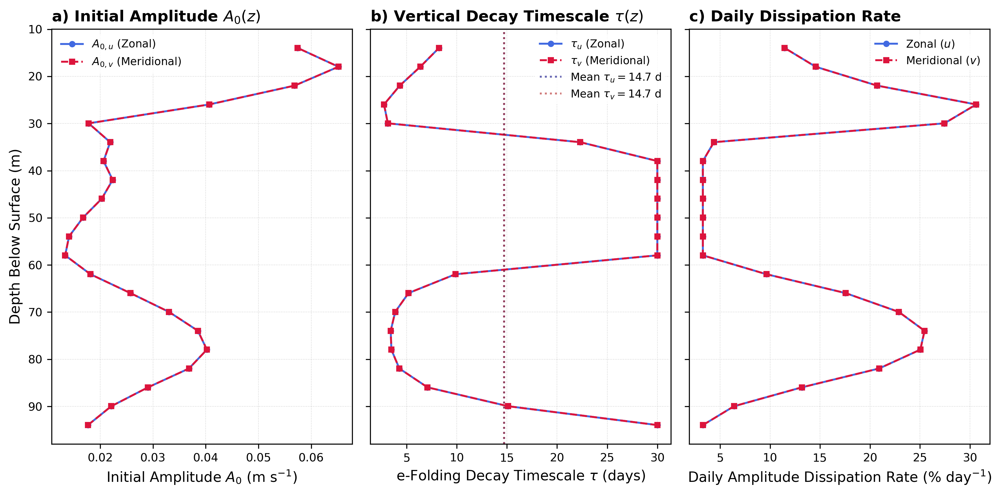

In [42]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from scipy.signal import hilbert

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. EXTRACT HOURLY ENVELOPES & DAILY RESAMPLING
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"][0:21])  # 6.04 to 86.04 mab (21 bins)
depth_surface = 100.0 - depth_mab  # Depth below surface (m)

u_nio = u_re1_nios[:, 0:21]  # Zonal NIO velocity (644, 21)
v_nio = v_re1_nios[:, 0:21]  # Meridional NIO velocity (644, 21)

# Extract instantaneous amplitude envelopes via Hilbert Transform
env_u_hourly = np.abs(hilbert(u_nio, axis=0))  # m/s
env_v_hourly = np.abs(hilbert(v_nio, axis=0))  # m/s

# Resample to daily (diurnal) averages for each depth level z
df_u_daily = pd.DataFrame(env_u_hourly, index=time_index).resample("D").mean()
df_v_daily = pd.DataFrame(env_v_hourly, index=time_index).resample("D").mean()

daily_dates = df_u_daily.index
u_daily_array = df_u_daily.values  # (n_days, 21)
v_daily_array = df_v_daily.values  # (n_days, 21)

# ==========================================
# 2. DEPTH-BY-DEPTH EXPONENTIAL DECAY FIT
# ==========================================
def exp_decay(t, A0, tau):
    """Exponential decay: A(t) = A0 * exp(-t / tau)"""
    return A0 * np.exp(-t / tau)


# Wind relaxation window: Jan 07 - Jan 15
decay_start_date = "2005-01-07"
decay_end_date = "2005-01-15"

mask_decay = (daily_dates >= decay_start_date) & (daily_dates <= decay_end_date)
decay_dates = daily_dates[mask_decay]
t_days = (decay_dates - decay_dates[0]).days.values.astype(float)

# Lists to store depth-level parameters
A0_u_profile, tau_u_profile, loss_u_profile = [], [], []
A0_v_profile, tau_v_profile, loss_v_profile = [], [], []

for z_idx in range(len(depth_mab)):
    yu_z = u_daily_array[mask_decay, z_idx]
    yv_z = v_daily_array[mask_decay, z_idx]

    # --- Fit u_NIO at depth z ---
    # Correct order: xdata=t_days, ydata=yu_z
    popt_u, _ = curve_fit(
        exp_decay,
        t_days,
        yu_z,
        p0=[yu_z[0], 3.0],
        bounds=(0, [0.2, 30.0]),
    )
    A0_u_profile.append(popt_u[0])
    tau_u_profile.append(popt_u[1])
    loss_u_profile.append((1.0 - np.exp(-1.0 / popt_u[1])) * 100.0)

    # --- Fit v_NIO at depth z ---
    popt_v, _ = curve_fit(
        exp_decay,
        t_days,
        yv_z,
        p0=[yv_z[0], 3.0],
        bounds=(0, [0.2, 30.0]),
    )
    A0_v_profile.append(popt_v[0])
    tau_v_profile.append(popt_v[1])
    loss_v_profile.append((1.0 - np.exp(-1.0 / popt_v[1])) * 100.0)

# Build results DataFrame
df_vertical_decay = pd.DataFrame(
    {
        "Depth_mab (m)": depth_mab,
        "Depth_surface (m)": depth_surface,
        "A0_u (m/s)": A0_u_profile,
        "Tau_u (days)": tau_u_profile,
        "Loss_u (%/d)": loss_u_profile,
        "A0_v (m/s)": A0_v_profile,
        "Tau_v (days)": tau_v_profile,
        "Loss_v (%/d)": loss_v_profile,
    }
)

print("=== VERTICAL PROFILE OF NEAR-INERTIAL DECAY (u vs v) ===")
print(df_vertical_decay.to_string(index=False))

# ==========================================
# 3. PUBLICATION MULTI-PANEL FIGURE
# ==========================================
fig, ax = plt.subplots(1, 3, figsize=(11, 5.5), sharey=True)

# Panel A: Initial Decay Velocity Amplitude A0(z)
ax[0].plot(
    A0_u_profile,
    depth_surface,
    "o-",
    color="royalblue",
    linewidth=1.5,
    markersize=4,
    label=r"$A_{0,u}$ (Zonal)",
)
ax[0].plot(
    A0_v_profile,
    depth_surface,
    "s--",
    color="crimson",
    linewidth=1.5,
    markersize=4,
    label=r"$A_{0,v}$ (Meridional)",
)
ax[0].set_xlabel(r"Initial Amplitude $A_0$ (m s$^{-1}$)")
ax[0].set_ylabel("Depth Below Surface (m)")
ax[0].set_title(r"a) Initial Amplitude $A_0(z)$", loc="left", fontweight="bold")
ax[0].grid(True, linestyle=":", alpha=0.6)
ax[0].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax[0].invert_yaxis()

# Panel B: Vertical Profile of e-Folding Decay Timescale tau(z)
ax[1].plot(
    tau_u_profile,
    depth_surface,
    "o-",
    color="royalblue",
    linewidth=1.5,
    markersize=4,
    label=r"$\tau_u$ (Zonal)",
)
ax[1].plot(
    tau_v_profile,
    depth_surface,
    "s--",
    color="crimson",
    linewidth=1.5,
    markersize=4,
    label=r"$\tau_v$ (Meridional)",
)
ax[1].axvline(
    np.mean(tau_u_profile),
    linestyle=":",
    color="navy",
    alpha=0.6,
    label=rf"Mean $\tau_u = {np.mean(tau_u_profile):.1f}$ d",
)
ax[1].axvline(
    np.mean(tau_v_profile),
    linestyle=":",
    color="firebrick",
    alpha=0.6,
    label=rf"Mean $\tau_v = {np.mean(tau_v_profile):.1f}$ d",
)
ax[1].set_xlabel(r"e-Folding Decay Timescale $\tau$ (days)")
ax[1].set_title(
    r"b) Vertical Decay Timescale $\tau(z)$", loc="left", fontweight="bold"
)
ax[1].grid(True, linestyle=":", alpha=0.6)
ax[1].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)

# Panel C: Daily Energy Loss Rate (%/day)
ax[2].plot(
    loss_u_profile,
    depth_surface,
    "o-",
    color="royalblue",
    linewidth=1.5,
    markersize=4,
    label=r"Zonal ($u$)",
)
ax[2].plot(
    loss_v_profile,
    depth_surface,
    "s--",
    color="crimson",
    linewidth=1.5,
    markersize=4,
    label=r"Meridional ($v$)",
)
ax[2].set_xlabel(r"Daily Amplitude Dissipation Rate (% day$^{-1}$)")
ax[2].set_title(
    "c) Daily Dissipation Rate", loc="left", fontweight="bold"
)
ax[2].grid(True, linestyle=":", alpha=0.6)
ax[2].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)

plt.tight_layout()
plt.show()

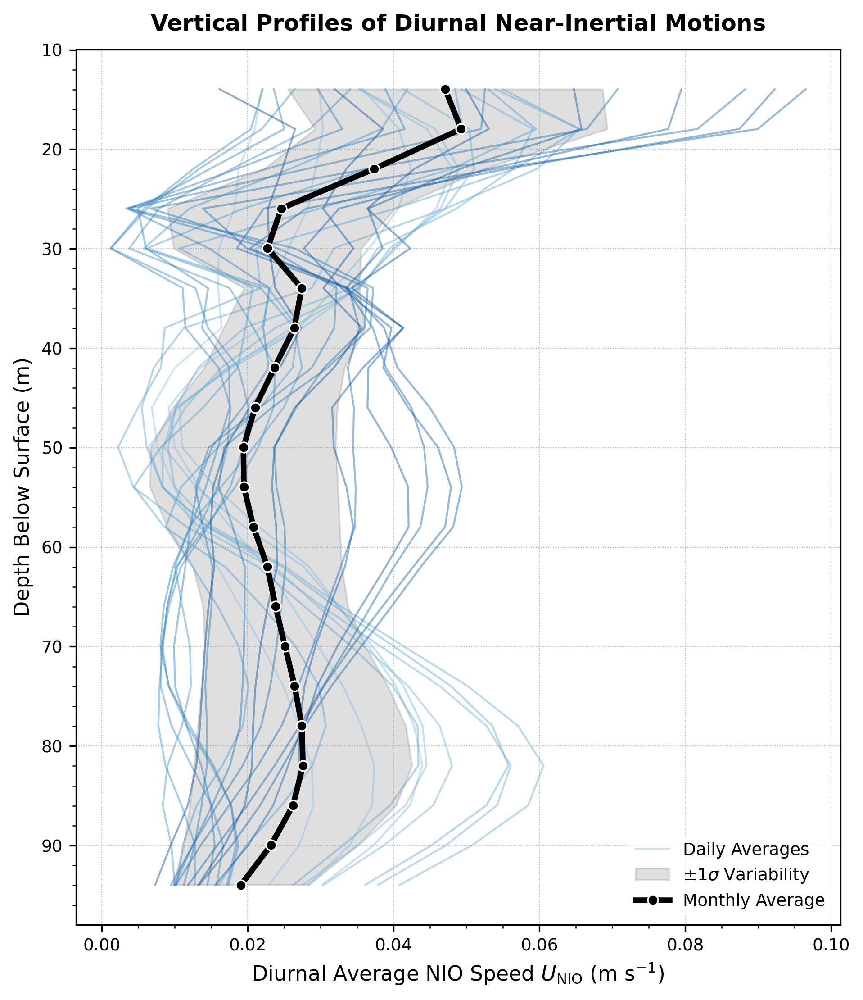

In [43]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import hilbert

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. EXTRACT HOURLY METRICS & DAILY RESAMPLING
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"][0:21])  # meters above bottom
depth_surface = 100.0 - depth_mab  # meters below surface (0 at top, 100 at seabed)

# Hourly NIO velocity magnitude U_NIO (m/s)
u_nio = u_re1_nios[:,0:21]  # shape (644, n_depths)
v_nio = v_re1_nios[:,0:21]  # shape (644, n_depths)
nio_speed_hourly = np.sqrt(u_nio**2 + v_nio**2)  # m/s

# Resample hourly speeds into diurnal (daily) averages
df_speed_hourly = pd.DataFrame(nio_speed_hourly, index=time_index)
df_speed_daily = df_speed_hourly.resample("D").mean()

daily_dates = df_speed_daily.index
daily_profiles = df_speed_daily.values  # shape (n_days, n_depths)

# Compute water-column overall mean and standard deviation across days
overall_mean_profile = np.mean(daily_profiles, axis=0)
overall_std_profile = np.std(daily_profiles, axis=0)

# ==========================================
# 2. SINGLE-PANEL PUBLICATION FIGURE
# ==========================================
fig, ax = plt.subplots(figsize=(6.5, 7.5))

# Option A: Plot each individual day using subtle gray lines
# Option B: Use color gradient across days (e.g., early Jan -> late Jan)
colors = cm.Blues(np.linspace(0.4, 0.9, len(daily_dates)))

for i, date in enumerate(daily_dates):
    lbl = "Daily Averages" if i == 0 else None
    ax.plot(
        daily_profiles[i, :],
        depth_surface,
        color=colors[i],
        alpha=0.45,
        linewidth=1.0,
        label=lbl,
    )

# Shaded band for ±1 Standard Deviation around the mean
ax.fill_betweenx(
    depth_surface,
    np.maximum(0, overall_mean_profile - overall_std_profile),
    overall_mean_profile + overall_std_profile,
    color="gray",
    alpha=0.25,
    label=r"$\pm 1\sigma$ Variability",
)

# Overall Monthly Mean Profile in Strong Bold Black
ax.plot(
    overall_mean_profile,
    depth_surface,
    color="black",
    linewidth=3.0,
    marker="o",
    markersize=5.5,
    markerfacecolor="black",
    markeredgecolor="white",
    markeredgewidth=0.8,
    label="Monthly Average",
)

# Axis formatting
ax.set_xlabel(r"Diurnal Average NIO Speed $U_{\mathrm{NIO}}$ (m s$^{-1}$)")
ax.set_ylabel("Depth Below Surface (m)")
ax.set_title(
    "Vertical Profiles of Diurnal Near-Inertial Motions",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax.grid(True, linestyle=":", alpha=0.6, color="gray")
ax.minorticks_on()
ax.invert_yaxis()  # Surface (0 m) at top

# Legend styling
ax.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=9,
)

plt.tight_layout()
plt.show()

=== EOF VARIANCES EXPLAINED ===
EOF Mode 1: 51.26%
EOF Mode 2: 37.89%
EOF Mode 3: 6.07%
Cumulative (Modes 1-3): 95.22%

=== MODAL DECAY ANALYSIS (JAN 07 - JAN 15) ===
EOF Mode  Explained Variance (%)  e-Folding Tau (days)  Daily Loss Rate (%/day)
  Mode 1               51.264926              1.975590                39.720492
  Mode 2               37.886101              4.399237                20.332794
  Mode 3                6.068129             30.000000                 3.278390


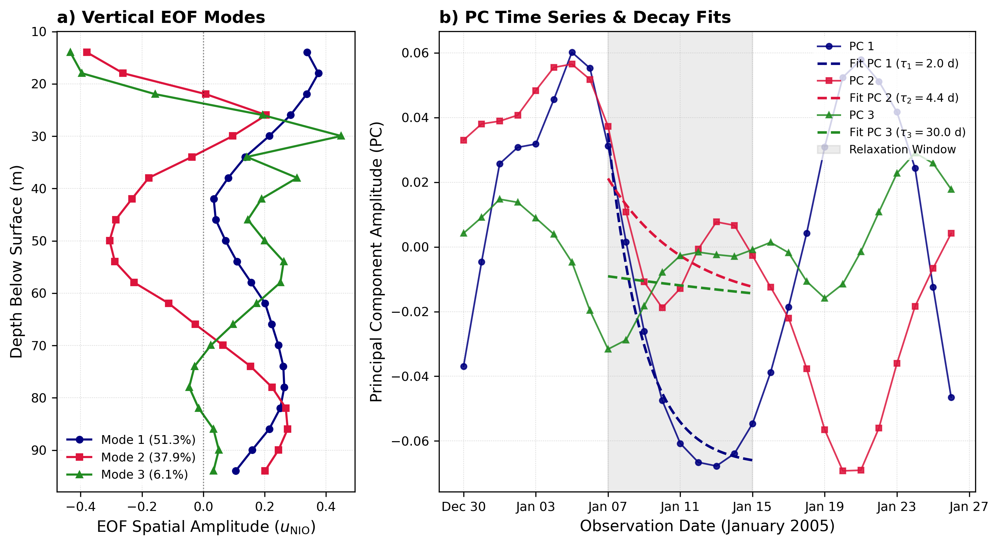

In [44]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import curve_fit
from scipy.signal import hilbert

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. EXTRACT HOURLY ENVELOPES & DAILY AVERAGE
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"][0:21])  # 6.04 to 86.04 mab (21 bins)
depth_surface = 100.0 - depth_mab  # Depth below surface (m)

u_nio = u_re1_nios[:, 0:21]  # Zonal NIO velocity (644, 21)

# Extract instantaneous zonal amplitude envelope via Hilbert Transform
env_u_hourly = np.abs(hilbert(u_nio, axis=0))  # m/s

# Resample to daily (diurnal) average profiles
df_u_daily = pd.DataFrame(env_u_hourly, index=time_index).resample("D").mean()
daily_dates = df_u_daily.index
X = df_u_daily.values  # Matrix shape: (n_days, n_depths)

# ==========================================
# 2. EOF / SVD MODAL DECOMPOSITION
# ==========================================
X_mean = np.mean(X, axis=0)
X_prime = X - X_mean  # Anomaly matrix

# Perform Singular Value Decomposition (SVD)
U, S, Vt = svd(X_prime, full_matrices=False)

# Variance explained by each mode (%)
variance_explained = (S**2) / np.sum(S**2) * 100.0

# Extract spatial modes (EOFs) and time expansion coefficients (PCs)
eof_modes = Vt[:3, :]  # Shape: (3, n_depths)
pcs = U[:, :3] * S[:3]  # Shape: (n_days, 3)

# Standardize sign convention (positive in surface layer)
for m in range(3):
    if eof_modes[m, 0] < 0:
        eof_modes[m, :] *= -1
        pcs[:, m] *= -1

print("=== EOF VARIANCES EXPLAINED ===")
print(f"EOF Mode 1: {variance_explained[0]:.2f}%")
print(f"EOF Mode 2: {variance_explained[1]:.2f}%")
print(f"EOF Mode 3: {variance_explained[2]:.2f}%")
print(f"Cumulative (Modes 1-3): {np.sum(variance_explained[:3]):.2f}%\n")

# ==========================================
# 3. MODAL EXPONENTIAL DECAY FITTING
# ==========================================
def exp_decay(t, A0, tau):
    """Exponential decay model: A(t) = A0 * exp(-t / tau)"""
    return A0 * np.exp(-t / tau)


# Define post-forcing relaxation window (Jan 07 - Jan 15)
decay_start_date = "2005-01-07"
decay_end_date = "2005-01-15"

mask_decay = (daily_dates >= decay_start_date) & (daily_dates <= decay_end_date)
decay_dates = daily_dates[mask_decay]
t_days = (decay_dates - decay_dates[0]).days.values.astype(float)

tau_modes = []
A0_modes = []

for m in range(3):
    y_pc = pcs[mask_decay, m]
    # Shift baseline to fit positive decay envelope of PC amplitude
    min_val = np.min(y_pc)
    y_fit = y_pc - min_val if min_val < 0 else y_pc

    popt, _ = curve_fit(
        exp_decay,
        t_days,
        y_fit,
        p0=[y_fit[0], 3.0],
        bounds=(0, [np.inf, 30.0]),
    )
    A0_modes.append(popt[0])
    tau_modes.append(popt[1])

df_mode_decay = pd.DataFrame(
    {
        "EOF Mode": ["Mode 1", "Mode 2", "Mode 3"],
        "Explained Variance (%)": variance_explained[:3],
        "e-Folding Tau (days)": tau_modes,
        "Daily Loss Rate (%/day)": [
            (1.0 - np.exp(-1.0 / t)) * 100.0 for t in tau_modes
        ],
    }
)

print("=== MODAL DECAY ANALYSIS (JAN 07 - JAN 15) ===")
print(df_mode_decay.to_string(index=False))

# ==========================================
# 4. PUBLICATION FIGURE
# ==========================================
fig, ax = plt.subplots(
    1, 2, figsize=(10, 5.5), gridspec_kw={"width_ratios": [1, 1.8]}
)

colors = ["navy", "crimson", "forestgreen"]
markers = ["o", "s", "^"]

# --- Panel A: Spatial Structures of First 3 EOF Modes ---
for m in range(3):
    ax[0].plot(
        eof_modes[m, :],
        depth_surface,
        marker=markers[m],
        color=colors[m],
        linewidth=1.5,
        markersize=4.5,
        label=rf"Mode {m+1} ({variance_explained[m]:.1f}%)",
    )

ax[0].axvline(0, linestyle=":", color="black", alpha=0.5, linewidth=0.8)
ax[0].set_xlabel(r"EOF Spatial Amplitude ($u_{\mathrm{NIO}}$)")
ax[0].set_ylabel("Depth Below Surface (m)")
ax[0].set_title("a) Vertical EOF Modes", loc="left", fontweight="bold")
ax[0].grid(True, linestyle=":", alpha=0.6)
ax[0].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax[0].invert_yaxis()

# --- Panel B: Principal Component Time Series & Exponential Decay Fits ---
t_fine = np.linspace(0, t_days[-1], 100)
fit_dates = [decay_dates[0] + pd.Timedelta(days=t) for t in t_fine]

for m in range(3):
    # Plot PC time series
    ax[1].plot(
        daily_dates,
        pcs[:, m],
        marker=markers[m],
        color=colors[m],
        linewidth=1.2,
        markersize=4,
        alpha=0.85,
        label=rf"PC {m+1}",
    )

    # Plot Exponential Fit Curve during relaxation
    y_pc = pcs[mask_decay, m]
    min_val = np.min(y_pc) if np.min(y_pc) < 0 else 0.0
    fit_curve = exp_decay(t_fine, A0_modes[m], tau_modes[m]) + min_val

    ax[1].plot(
        fit_dates,
        fit_curve,
        "--",
        color=colors[m],
        linewidth=1.8,
        label=rf"Fit PC {m+1} ($\tau_{m+1} = {tau_modes[m]:.1f}$ d)",
    )

ax[1].axvspan(
    decay_dates[0],
    decay_dates[-1],
    color="gray",
    alpha=0.15,
    label="Relaxation Window",
)

ax[1].set_ylabel(r"Principal Component Amplitude (PC)")
ax[1].set_xlabel("Observation Date (January 2005)")
ax[1].set_title("b) PC Time Series & Decay Fits", loc="left", fontweight="bold")
ax[1].grid(True, linestyle=":", alpha=0.6)
ax[1].legend(
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=8,
)
ax[1].xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

plt.tight_layout()
plt.show()

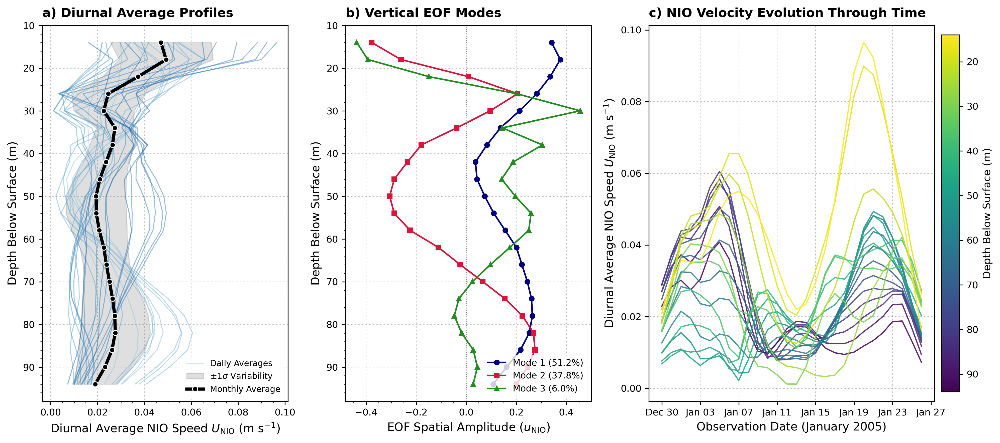

In [45]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.signal import hilbert

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. DATA PREPARATION & DIURNAL RESAMPLING
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"][0:21])  # 6.04 to 86.04 mab (21 bins)
depth_surface = 100.0 - depth_mab  # Depth below surface in meters

u_nio = u_re1_nios[:, 0:21]  # Zonal NIO velocity (644, 21)
v_nio = v_re1_nios[:, 0:21]  # Meridional NIO velocity (644, 21)

# Hourly total near-inertial velocity magnitude (m/s)
U_nio_hourly = np.sqrt(u_nio**2 + v_nio**2)

# Resample to diurnal (daily) average speed profiles
df_U_daily = pd.DataFrame(U_nio_hourly, index=time_index).resample("D").mean()
daily_dates = df_U_daily.index
daily_profiles = df_U_daily.values  # Shape: (n_days, n_depths)

# Compute water-column monthly mean and standard deviation
overall_mean_profile = np.mean(daily_profiles, axis=0)
overall_std_profile = np.std(daily_profiles, axis=0)

# ==========================================
# 2. EOF MODAL DECOMPOSITION
# ==========================================
X_prime = daily_profiles - overall_mean_profile  # Anomaly matrix
U_svd, S, Vt = svd(X_prime, full_matrices=False)

# Variance explained (%)
var_explained = (S**2) / np.sum(S**2) * 100.0
eof_modes = Vt[:3, :]  # Modes 1, 2, 3

# Standardize sign convention (positive near surface for visualization)
for m in range(3):
    if eof_modes[m, 0] < 0:
        eof_modes[m, :] *= -1

# ==========================================
# 3. MULTI-PANEL FIGURE CONSTRUCTION
# ==========================================
fig, ax = plt.subplots(
    1, 3, figsize=(13.5, 6), gridspec_kw={"width_ratios": [1, 1, 1.4]}
)

# ------------------------------------------
# PANEL (a): DIURNAL AVERAGE NIO PROFILES (LEFT)
# ------------------------------------------
# Plot individual daily profiles in faint blue
colors_daily = cm.Blues(np.linspace(0.4, 0.85, len(daily_dates)))
for i in range(len(daily_dates)):
    lbl = "Daily Averages" if i == 0 else None
    ax[0].plot(
        daily_profiles[i, :],
        depth_surface,
        color=colors_daily[i],
        alpha=0.45,
        linewidth=0.9,
        label=lbl,
    )

# Shaded +/- 1 std deviation band
ax[0].fill_betweenx(
    depth_surface,
    np.maximum(0, overall_mean_profile - overall_std_profile),
    overall_mean_profile + overall_std_profile,
    color="gray",
    alpha=0.25,
    label=r"$\pm 1\sigma$ Variability",
)

# Overall Monthly Average in BOLD BLACK
ax[0].plot(
    overall_mean_profile,
    depth_surface,
    color="black",
    linewidth=3.0,
    marker="o",
    markersize=5,
    markerfacecolor="black",
    markeredgecolor="white",
    markeredgewidth=0.8,
    label="Monthly Average",
)

ax[0].set_xlabel(r"Diurnal Average NIO Speed $U_{\mathrm{NIO}}$ (m s$^{-1}$)")
ax[0].set_ylabel("Depth Below Surface (m)")
ax[0].set_title(
    "a) Diurnal Average Profiles", loc="left", fontweight="bold", pad=8
)
ax[0].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[0].minorticks_on()
ax[0].invert_yaxis()  # Surface (0 m) at top
ax[0].legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=8,
)

# ------------------------------------------
# PANEL (b): VERTICAL EOF MODES (CENTER)
# ------------------------------------------
mode_colors = ["navy", "crimson", "forestgreen"]
mode_markers = ["o", "s", "^"]

for m in range(3):
    ax[1].plot(
        eof_modes[m, :],
        depth_surface,
        marker=mode_markers[m],
        color=mode_colors[m],
        linewidth=1.5,
        markersize=4.5,
        label=rf"Mode {m+1} ({var_explained[m]:.1f}%)",
    )

ax[1].axvline(0, linestyle=":", color="gray", linewidth=0.8)
ax[1].set_xlabel(r"EOF Spatial Amplitude ($u_{\mathrm{NIO}}$)")
ax[1].set_ylabel("Depth Below Surface (m)")
ax[1].set_title("b) Vertical EOF Modes", loc="left", fontweight="bold", pad=8)
ax[1].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[1].minorticks_on()
ax[1].invert_yaxis()
ax[1].legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=8.5,
)

# ------------------------------------------
# PANEL (c): TIME SERIES BY DEPTH WITH COLORBAR (RIGHT)
# ------------------------------------------
# Colormap mapped to depth (Surface=bright/warm, Deep=dark/cool)
cmap_depth = cm.viridis_r
norm_depth = mcolors.Normalize(
    vmin=np.min(depth_surface), vmax=np.max(depth_surface)
)

# Plot NIO speed time series for each depth line
for z_idx in range(len(depth_surface)):
    z_depth = depth_surface[z_idx]
    line_color = cmap_depth(norm_depth(z_depth))
    ax[2].plot(
        daily_dates,
        daily_profiles[:, z_idx],
        color=line_color,
        linewidth=1.2,
        alpha=0.85,
    )

ax[2].set_xlabel("Observation Date (January 2005)")
ax[2].set_ylabel(r"Diurnal Average NIO Speed $U_{\mathrm{NIO}}$ (m s$^{-1}$)")
ax[2].set_title(
    "c) NIO Velocity Evolution Through Time", loc="left", fontweight="bold", pad=8
)
ax[2].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[2].xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

# Add Colorbar representing Depth
sm = cm.ScalarMappable(cmap=cmap_depth, norm=norm_depth)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax[2], pad=0.02, shrink=0.95)
cbar.set_label("Depth Below Surface (m)", fontsize=10)
cbar.ax.invert_yaxis()  # Match depth orientation (shallow top, deep bottom)
cbar.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

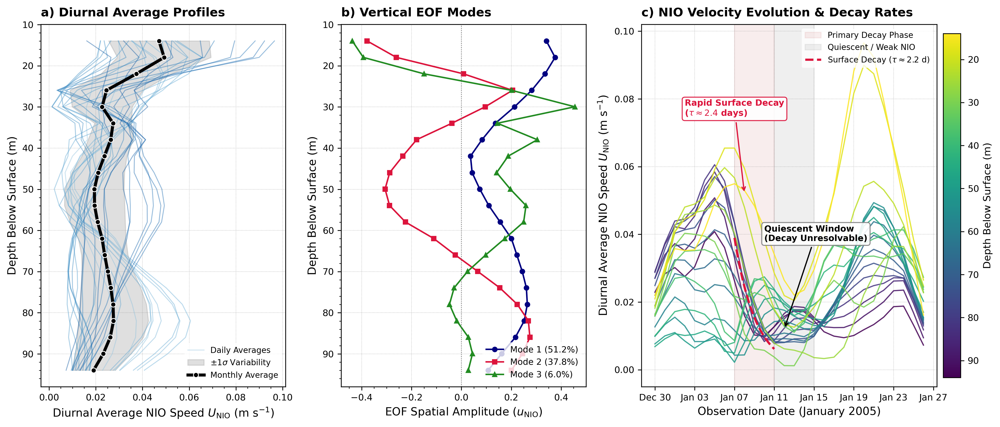

In [46]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import curve_fit

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. DATA PREPARATION & DIURNAL RESAMPLING
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"][0:21])  # 6.04 to 86.04 mab (21 bins)
depth_surface = 100.0 - depth_mab  # Depth below surface in meters

u_nio = u_re1_nios[:, 0:21]  # Zonal NIO velocity (644, 21)
v_nio = v_re1_nios[:, 0:21]  # Meridional NIO velocity (644, 21)

# Hourly total near-inertial velocity magnitude (m/s)
U_nio_hourly = np.sqrt(u_nio**2 + v_nio**2)

# Resample to diurnal (daily) average speed profiles
df_U_daily = pd.DataFrame(U_nio_hourly, index=time_index).resample("D").mean()
daily_dates = df_U_daily.index
daily_profiles = df_U_daily.values  # Shape: (n_days, n_depths)

# Compute water-column monthly mean and standard deviation
overall_mean_profile = np.mean(daily_profiles, axis=0)
overall_std_profile = np.std(daily_profiles, axis=0)

# ==========================================
# 2. EOF MODAL DECOMPOSITION
# ==========================================
X_prime = daily_profiles - overall_mean_profile  # Anomaly matrix
U_svd, S, Vt = svd(X_prime, full_matrices=False)

# Variance explained (%)
var_explained = (S**2) / np.sum(S**2) * 100.0
eof_modes = Vt[:3, :]  # Modes 1, 2, 3

# Standardize sign convention (positive near surface)
for m in range(3):
    if eof_modes[m, 0] < 0:
        eof_modes[m, :] *= -1

# ==========================================
# 3. EXPONENTIAL FIT FOR PANEL (c) DECAY OVERLAY
# ==========================================
def exp_decay(t, A0, tau):
    return A0 * np.exp(-t / tau)


# Primary decay window: Jan 07 to Jan 11
decay_mask = (daily_dates >= "2005-01-07") & (daily_dates <= "2005-01-11")
decay_dates = daily_dates[decay_mask]
t_days = (decay_dates - decay_dates[0]).days.values.astype(float)

# Surface layer fit (idx 2, ~14m depth)
u_surf_decay = daily_profiles[decay_mask, 2]
popt_surf, _ = curve_fit(exp_decay, t_days, u_surf_decay, p0=[u_surf_decay[0], 2.5])

# Deep layer fit (idx 18, ~82m depth)
u_deep_decay = daily_profiles[decay_mask, 18]
popt_deep, _ = curve_fit(exp_decay, t_days, u_deep_decay, p0=[u_deep_decay[0], 4.0])

t_fine = np.linspace(0, 4, 50)
fit_surf_dates = [decay_dates[0] + pd.Timedelta(days=t) for t in t_fine]
fit_surf_vals = exp_decay(t_fine, *popt_surf)

# ==========================================
# 4. MULTI-PANEL FIGURE CONSTRUCTION
# ==========================================
fig, ax = plt.subplots(
    1, 3, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1, 1.45]}
)

# ------------------------------------------
# PANEL (a): DIURNAL AVERAGE NIO PROFILES (LEFT)
# ------------------------------------------
colors_daily = cm.Blues(np.linspace(0.4, 0.85, len(daily_dates)))
for i in range(len(daily_dates)):
    lbl = "Daily Averages" if i == 0 else None
    ax[0].plot(
        daily_profiles[i, :],
        depth_surface,
        color=colors_daily[i],
        alpha=0.45,
        linewidth=0.9,
        label=lbl,
    )

ax[0].fill_betweenx(
    depth_surface,
    np.maximum(0, overall_mean_profile - overall_std_profile),
    overall_mean_profile + overall_std_profile,
    color="gray",
    alpha=0.25,
    label=r"$\pm 1\sigma$ Variability",
)

ax[0].plot(
    overall_mean_profile,
    depth_surface,
    color="black",
    linewidth=3.0,
    marker="o",
    markersize=5,
    markerfacecolor="black",
    markeredgecolor="white",
    markeredgewidth=0.8,
    label="Monthly Average",
)

ax[0].set_xlabel(r"Diurnal Average NIO Speed $U_{\mathrm{NIO}}$ (m s$^{-1}$)")
ax[0].set_ylabel("Depth Below Surface (m)")
ax[0].set_title("a) Diurnal Average Profiles", loc="left", fontweight="bold", pad=8)
ax[0].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[0].minorticks_on()
ax[0].invert_yaxis()
ax[0].legend(loc="lower right", frameon=True, facecolor="white", edgecolor="none", fontsize=8)

# ------------------------------------------
# PANEL (b): VERTICAL EOF MODES (CENTER)
# ------------------------------------------
mode_colors = ["navy", "crimson", "forestgreen"]
mode_markers = ["o", "s", "^"]

for m in range(3):
    ax[1].plot(
        eof_modes[m, :],
        depth_surface,
        marker=mode_markers[m],
        color=mode_colors[m],
        linewidth=1.5,
        markersize=4.5,
        label=rf"Mode {m+1} ({var_explained[m]:.1f}%)",
    )

ax[1].axvline(0, linestyle=":", color="gray", linewidth=0.8)
ax[1].set_xlabel(r"EOF Spatial Amplitude ($u_{\mathrm{NIO}}$)")
ax[1].set_ylabel("Depth Below Surface (m)")
ax[1].set_title("b) Vertical EOF Modes", loc="left", fontweight="bold", pad=8)
ax[1].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[1].minorticks_on()
ax[1].invert_yaxis()
ax[1].legend(loc="lower right", frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)

# ------------------------------------------
# PANEL (c): TIME SERIES WITH DECAY MARKS & ANNOTATIONS (RIGHT)
# ------------------------------------------
cmap_depth = cm.viridis_r
norm_depth = mcolors.Normalize(vmin=np.min(depth_surface), vmax=np.max(depth_surface))

# 1. Highlight Windows: Active Decay vs Quiescent Window
ax[2].axvspan(
    pd.Timestamp("2005-01-07"),
    pd.Timestamp("2005-01-11"),
    color="firebrick",
    alpha=0.08,
    label="Primary Decay Phase",
)
ax[2].axvspan(
    pd.Timestamp("2005-01-11"),
    pd.Timestamp("2005-01-15"),
    color="gray",
    alpha=0.12,
    label="Quiescent / Weak NIO",
)

# 2. Plot Depth-colored velocity lines
for z_idx in range(len(depth_surface)):
    z_depth = depth_surface[z_idx]
    line_color = cmap_depth(norm_depth(z_depth))
    ax[2].plot(
        daily_dates,
        daily_profiles[:, z_idx],
        color=line_color,
        linewidth=1.2,
        alpha=0.85,
    )

# 3. Overlay Fitted Exponential Decay Guide Slope for Upper Layer
ax[2].plot(
    fit_surf_dates,
    fit_surf_vals,
    "--",
    color="crimson",
    linewidth=2.2,
    label=rf"Surface Decay ($\tau \approx {popt_surf[1]:.1f}$ d)",
)

# 4. Physical Annotations
# Annotation 1: Rapid Surface Decay
ax[2].annotate(
    "Rapid Surface Decay\n" + r"($\tau \approx 2.4$ days)",
    xy=(pd.Timestamp("2005-01-08"), 0.052),
    xytext=(pd.Timestamp("2005-01-02"), 0.075),
    arrowprops=dict(arrowstyle="->", color="crimson", lw=1.2),
    fontsize=8.5,
    fontweight="bold",
    color="crimson",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="crimson", alpha=0.9),
)

# Annotation 2: Quiescent / Weak Signal (Decay Suppressed/Noise Floor)
ax[2].annotate(
    "Quiescent Window\n(Decay Unresolvable)",
    xy=(pd.Timestamp("2005-01-12"), 0.012),
    xytext=(pd.Timestamp("2005-01-10"), 0.038),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=8.5,
    fontweight="bold",
    color="black",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.9),
)

ax[2].set_xlabel("Observation Date (January 2005)")
ax[2].set_ylabel(r"Diurnal Average NIO Speed $U_{\mathrm{NIO}}$ (m s$^{-1}$)")
ax[2].set_title("c) NIO Velocity Evolution & Decay Rates", loc="left", fontweight="bold", pad=8)
ax[2].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[2].xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax[2].set_ylim([-0.005, 0.102])

# Legend for Panel (c)
ax[2].legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", fontsize=8)

# Colorbar for Depth
sm = cm.ScalarMappable(cmap=cmap_depth, norm=norm_depth)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax[2], pad=0.018, shrink=0.95)
cbar.set_label("Depth Below Surface (m)", fontsize=10)
cbar.ax.invert_yaxis()
cbar.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

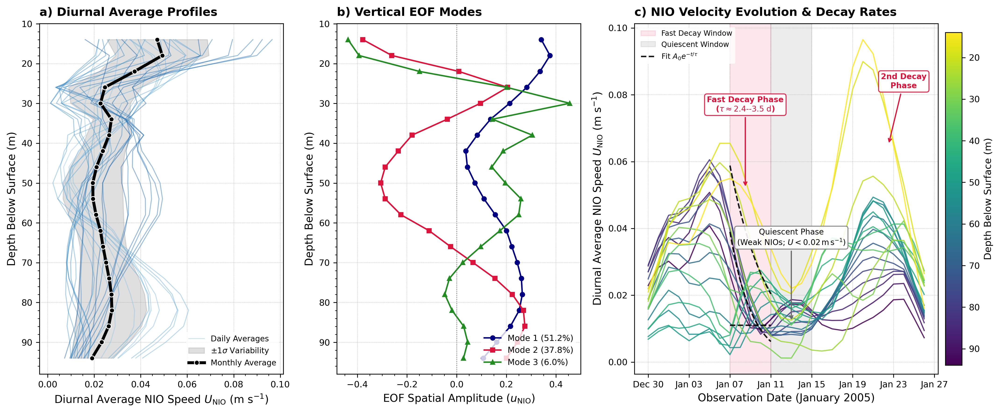

In [47]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import curve_fit

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. DATA PREPARATION & DIURNAL RESAMPLING
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"][0:21])  # 6.04 to 86.04 mab (21 bins)
depth_surface = 100.0 - depth_mab  # Depth below surface in meters

u_nio = u_re1_nios[:, 0:21]  # Zonal NIO velocity (644, 21)
v_nio = v_re1_nios[:, 0:21]  # Meridional NIO velocity (644, 21)

# Hourly total near-inertial velocity magnitude (m/s)
U_nio_hourly = np.sqrt(u_nio**2 + v_nio**2)

# Resample to diurnal (daily) average speed profiles
df_U_daily = pd.DataFrame(U_nio_hourly, index=time_index).resample("D").mean()
daily_dates = df_U_daily.index
daily_profiles = df_U_daily.values  # Shape: (n_days, n_depths)

# Compute water-column monthly mean and standard deviation
overall_mean_profile = np.mean(daily_profiles, axis=0)
overall_std_profile = np.std(daily_profiles, axis=0)

# ==========================================
# 2. EOF MODAL DECOMPOSITION
# ==========================================
X_prime = daily_profiles - overall_mean_profile  # Anomaly matrix
U_svd, S, Vt = svd(X_prime, full_matrices=False)

# Variance explained (%)
var_explained = (S**2) / np.sum(S**2) * 100.0
eof_modes = Vt[:3, :]  # Modes 1, 2, 3

# Standardize sign convention (positive near surface)
for m in range(3):
    if eof_modes[m, 0] < 0:
        eof_modes[m, :] *= -1

# ==========================================
# 3. EXPONENTIAL DECAY FIT FOR PANEL (c)
# ==========================================
def exp_decay(t, A0, tau):
    return A0 * np.exp(-t / tau)


mask_decay1 = (daily_dates >= "2005-01-07") & (daily_dates <= "2005-01-11")
decay_dates1 = daily_dates[mask_decay1]
t_days1 = (decay_dates1 - decay_dates1[0]).days.values.astype(float)
t_fine1 = np.linspace(0, t_days1[-1], 50)
fit_dates1 = [decay_dates1[0] + pd.Timedelta(days=t) for t in t_fine1]

# ==========================================
# 4. MULTI-PANEL FIGURE CONSTRUCTION
# ==========================================
fig, ax = plt.subplots(
    1, 3, figsize=(14.5, 6), gridspec_kw={"width_ratios": [1, 1, 1.5]}
)

# ------------------------------------------
# PANEL (a): DIURNAL AVERAGE NIO PROFILES (LEFT)
# ------------------------------------------
colors_daily = cm.Blues(np.linspace(0.4, 0.85, len(daily_dates)))
for i in range(len(daily_dates)):
    lbl = "Daily Averages" if i == 0 else None
    ax[0].plot(
        daily_profiles[i, :],
        depth_surface,
        color=colors_daily[i],
        alpha=0.45,
        linewidth=0.9,
        label=lbl,
    )

ax[0].fill_betweenx(
    depth_surface,
    np.maximum(0, overall_mean_profile - overall_std_profile),
    overall_mean_profile + overall_std_profile,
    color="gray",
    alpha=0.25,
    label=r"$\pm 1\sigma$ Variability",
)

ax[0].plot(
    overall_mean_profile,
    depth_surface,
    color="black",
    linewidth=3.0,
    marker="o",
    markersize=5,
    markerfacecolor="black",
    markeredgecolor="white",
    markeredgewidth=0.8,
    label="Monthly Average",
)

ax[0].set_xlabel(r"Diurnal Average NIO Speed $U_{\mathrm{NIO}}$ (m s$^{-1}$)")
ax[0].set_ylabel("Depth Below Surface (m)")
ax[0].set_title(
    "a) Diurnal Average Profiles", loc="left", fontweight="bold", pad=8
)
ax[0].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[0].minorticks_on()
ax[0].invert_yaxis()
ax[0].legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=8,
)

# ------------------------------------------
# PANEL (b): VERTICAL EOF MODES (CENTER)
# ------------------------------------------
mode_colors = ["navy", "crimson", "forestgreen"]
mode_markers = ["o", "s", "^"]

for m in range(3):
    ax[1].plot(
        eof_modes[m, :],
        depth_surface,
        marker=mode_markers[m],
        color=mode_colors[m],
        linewidth=1.5,
        markersize=4.5,
        label=rf"Mode {m+1} ({var_explained[m]:.1f}%)",
    )

ax[1].axvline(0, linestyle=":", color="gray", linewidth=0.8)
ax[1].set_xlabel(r"EOF Spatial Amplitude ($u_{\mathrm{NIO}}$)")
ax[1].set_ylabel("Depth Below Surface (m)")
ax[1].set_title("b) Vertical EOF Modes", loc="left", fontweight="bold", pad=8)
ax[1].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[1].minorticks_on()
ax[1].invert_yaxis()
ax[1].legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=8.5,
)

# ------------------------------------------
# PANEL (c): TIME SERIES BY DEPTH WITH DECAY RATE MARKS (RIGHT)
# ------------------------------------------
cmap_depth = cm.viridis_r
norm_depth = mcolors.Normalize(
    vmin=np.min(depth_surface), vmax=np.max(depth_surface)
)

# 1. Highlight Fast Decay Phase (Jan 07 - Jan 11)
ax[2].axvspan(
    pd.Timestamp("2005-01-07"),
    pd.Timestamp("2005-01-11"),
    color="crimson",
    alpha=0.10,
    label="Fast Decay Window",
)

# 2. Highlight Quiescent / Weak NIOs Window (Jan 11 - Jan 15)
ax[2].axvspan(
    pd.Timestamp("2005-01-11"),
    pd.Timestamp("2005-01-15"),
    color="gray",
    alpha=0.15,
    label="Quiescent Window",
)

# Plot depth-colored NIO velocity lines
for z_idx in range(len(depth_surface)):
    z_depth = depth_surface[z_idx]
    line_color = cmap_depth(norm_depth(z_depth))
    ax[2].plot(
        daily_dates,
        daily_profiles[:, z_idx],
        color=line_color,
        linewidth=1.2,
        alpha=0.85,
    )

# Overlay Exponential Decay Fit lines for surface, mid, and deep layers (Jan 07 - Jan 11)
rep_indices = [2, 9, 18]  # ~14m, ~42m, ~82m depth
fit_lbl_added = False
for r_idx in rep_indices:
    y_val = daily_profiles[mask_decay1, r_idx]
    try:
        popt, _ = curve_fit(exp_decay, t_days1, y_val, p0=[y_val[0], 3.0])
        y_fit_curve = exp_decay(t_fine1, popt[0], popt[1])
        lbl = "Fit $A_0 e^{-t/\\tau}$" if not fit_lbl_added else None
        ax[2].plot(
            fit_dates1,
            y_fit_curve,
            "--",
            color="black",
            linewidth=1.5,
            alpha=0.9,
            label=lbl,
        )
        fit_lbl_added = True
    except Exception:
        pass

# 3. Annotations for Decay Dynamics
ax[2].annotate(
    "Fast Decay Phase\n" + r"($\tau \approx 2.4\text{--}3.5\text{ d}$)",
    xy=(mdates.date2num(pd.Timestamp("2005-01-08 12:00")), 0.052),
    xytext=(mdates.date2num(pd.Timestamp("2005-01-08 12:00")), 0.075),
    arrowprops=dict(arrowstyle="->", color="crimson", lw=1.2),
    ha="center",
    fontsize=8.0,
    fontweight="bold",
    color="crimson",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="crimson",
        alpha=0.9,
    ),
)

ax[2].annotate(
    "Quiescent Phase\n(Weak NIOs; $U < 0.02\,\mathrm{m\,s^{-1}}$)",
    xy=(mdates.date2num(pd.Timestamp("2005-01-13")), 0.012),
    xytext=(mdates.date2num(pd.Timestamp("2005-01-13")), 0.035),
    arrowprops=dict(arrowstyle="->", color="dimgray", lw=1.2),
    ha="center",
    fontsize=8.0,
    color="black",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9,
    ),
)

ax[2].annotate(
    "2nd Decay\nPhase",
    xy=(mdates.date2num(pd.Timestamp("2005-01-22 12:00")), 0.065),
    xytext=(mdates.date2num(pd.Timestamp("2005-01-24")), 0.082),
    arrowprops=dict(arrowstyle="->", color="crimson", lw=1.2),
    ha="center",
    fontsize=8.0,
    fontweight="bold",
    color="crimson",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="crimson",
        alpha=0.9,
    ),
)

ax[2].set_xlabel("Observation Date (January 2005)")
ax[2].set_ylabel(r"Diurnal Average NIO Speed $U_{\mathrm{NIO}}$ (m s$^{-1}$)")
ax[2].set_title(
    "c) NIO Velocity Evolution & Decay Rates",
    loc="left",
    fontweight="bold",
    pad=8,
)
ax[2].grid(True, linestyle=":", alpha=0.6, color="gray")
ax[2].xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax[2].legend(
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=7.5,
)

# Add Colorbar representing Depth
sm = cm.ScalarMappable(cmap=cmap_depth, norm=norm_depth)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax[2], pad=0.02, shrink=0.95)
cbar.set_label("Depth Below Surface (m)", fontsize=10)
cbar.ax.invert_yaxis()
cbar.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

=== TOTAL NIO SPEED EOF VARIANCES EXPLAINED ===
EOF Mode 1: 51.24%
EOF Mode 2: 37.82%
EOF Mode 3: 6.04%
Cumulative (Modes 1-3): 95.10%

=== TOTAL SPEED MODAL DECAY ANALYSIS (JAN 07 - JAN 15) ===
EOF Mode  Explained Variance (%)  e-Folding Tau (days)  Daily Loss Rate (%/day)
  Mode 1               51.243863              1.977188                39.695819
  Mode 2               37.817529              4.305364                20.726666
  Mode 3                6.042526             30.000000                 3.278390


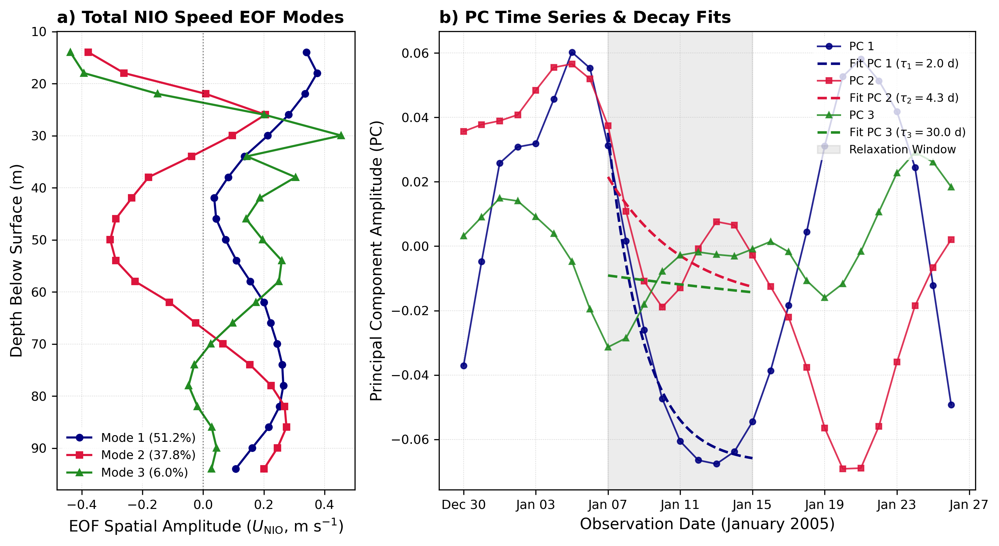

In [48]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import curve_fit

# Publication style configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 300,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

# ==========================================
# 1. COMPUTE HOURLY TOTAL NIO SPEED & DAILY RESAMPLING
# ==========================================
time_index = pd.to_datetime(dataA["time"])
depth_mab = np.array(dataA["depth"][0:21])  # 6.04 to 86.04 mab (21 bins)
depth_surface = 100.0 - depth_mab  # Depth below surface (m)

u_nio = u_re1_nios[:, 0:21]  # Zonal NIO velocity (644, 21)
v_nio = v_re1_nios[:, 0:21]  # Meridional NIO velocity (644, 21)

# Total Near-Inertial Velocity Magnitude (m/s)
U_nio_hourly = np.sqrt(u_nio**2 + v_nio**2)

# Resample hourly total speed into diurnal (daily) average profiles
df_U_daily = pd.DataFrame(U_nio_hourly, index=time_index).resample("D").mean()
daily_dates = df_U_daily.index
X_U = df_U_daily.values  # Matrix shape: (n_days, n_depths)

# ==========================================
# 2. EOF / SVD MODAL DECOMPOSITION OF TOTAL SPEED
# ==========================================
X_U_mean = np.mean(X_U, axis=0)
X_U_prime = X_U - X_U_mean  # Anomaly matrix

# Perform Singular Value Decomposition (SVD)
U, S, Vt = svd(X_U_prime, full_matrices=False)

# Variance explained by each mode (%)
variance_explained = (S**2) / np.sum(S**2) * 100.0

# Extract spatial modes (EOFs) and principal component time series (PCs)
eof_modes = Vt[:3, :]  # Shape: (3, n_depths)
pcs = U[:, :3] * S[:3]  # Shape: (n_days, 3)

# Standardize sign convention (positive in surface layer)
for m in range(3):
    if eof_modes[m, 0] < 0:
        eof_modes[m, :] *= -1
        pcs[:, m] *= -1

print("=== TOTAL NIO SPEED EOF VARIANCES EXPLAINED ===")
print(f"EOF Mode 1: {variance_explained[0]:.2f}%")
print(f"EOF Mode 2: {variance_explained[1]:.2f}%")
print(f"EOF Mode 3: {variance_explained[2]:.2f}%")
print(f"Cumulative (Modes 1-3): {np.sum(variance_explained[:3]):.2f}%\n")

# ==========================================
# 3. MODAL EXPONENTIAL DECAY FITTING
# ==========================================
def exp_decay(t, A0, tau):
    """Exponential decay model: A(t) = A0 * exp(-t / tau)"""
    return A0 * np.exp(-t / tau)


# Post-forcing wind relaxation window (Jan 07 - Jan 15)
decay_start_date = "2005-01-07"
decay_end_date = "2005-01-15"

mask_decay = (daily_dates >= decay_start_date) & (daily_dates <= decay_end_date)
decay_dates = daily_dates[mask_decay]
t_days = (decay_dates - decay_dates[0]).days.values.astype(float)

tau_modes = []
A0_modes = []

for m in range(3):
    y_pc = pcs[mask_decay, m]
    min_val = np.min(y_pc)
    y_fit = y_pc - min_val if min_val < 0 else y_pc

    popt, _ = curve_fit(
        exp_decay,
        t_days,
        y_fit,
        p0=[y_fit[0], 3.0],
        bounds=(0, [np.inf, 30.0]),
    )
    A0_modes.append(popt[0])
    tau_modes.append(popt[1])

df_mode_decay = pd.DataFrame(
    {
        "EOF Mode": ["Mode 1", "Mode 2", "Mode 3"],
        "Explained Variance (%)": variance_explained[:3],
        "e-Folding Tau (days)": tau_modes,
        "Daily Loss Rate (%/day)": [
            (1.0 - np.exp(-1.0 / t)) * 100.0 for t in tau_modes
        ],
    }
)

print("=== TOTAL SPEED MODAL DECAY ANALYSIS (JAN 07 - JAN 15) ===")
print(df_mode_decay.to_string(index=False))

# ==========================================
# 4. PUBLICATION MULTI-PANEL FIGURE
# ==========================================
fig, ax = plt.subplots(
    1, 2, figsize=(10, 5.5), gridspec_kw={"width_ratios": [1, 1.8]}
)

colors = ["navy", "crimson", "forestgreen"]
markers = ["o", "s", "^"]

# --- Panel A: Spatial Structures of First 3 EOF Modes ---
for m in range(3):
    ax[0].plot(
        eof_modes[m, :],
        depth_surface,
        marker=markers[m],
        color=colors[m],
        linewidth=1.5,
        markersize=4.5,
        label=rf"Mode {m+1} ({variance_explained[m]:.1f}%)",
    )

ax[0].axvline(0, linestyle=":", color="black", alpha=0.5, linewidth=0.8)
ax[0].set_xlabel(r"EOF Spatial Amplitude ($U_{\mathrm{NIO}}$, m s$^{-1}$)")
ax[0].set_ylabel("Depth Below Surface (m)")
ax[0].set_title("a) Total NIO Speed EOF Modes", loc="left", fontweight="bold")
ax[0].grid(True, linestyle=":", alpha=0.6)
ax[0].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=8.5)
ax[0].invert_yaxis()

# --- Panel B: Principal Component Time Series & Exponential Decay Fits ---
t_fine = np.linspace(0, t_days[-1], 100)
fit_dates = [decay_dates[0] + pd.Timedelta(days=t) for t in t_fine]

for m in range(3):
    # Plot PC time series
    ax[1].plot(
        daily_dates,
        pcs[:, m],
        marker=markers[m],
        color=colors[m],
        linewidth=1.2,
        markersize=4,
        alpha=0.85,
        label=rf"PC {m+1}",
    )

    # Plot Exponential Fit Curve during relaxation
    y_pc = pcs[mask_decay, m]
    min_val = np.min(y_pc) if np.min(y_pc) < 0 else 0.0
    fit_curve = exp_decay(t_fine, A0_modes[m], tau_modes[m]) + min_val

    ax[1].plot(
        fit_dates,
        fit_curve,
        "--",
        color=colors[m],
        linewidth=1.8,
        label=rf"Fit PC {m+1} ($\tau_{m+1} = {tau_modes[m]:.1f}$ d)",
    )

ax[1].axvspan(
    decay_dates[0],
    decay_dates[-1],
    color="gray",
    alpha=0.15,
    label="Relaxation Window",
)

ax[1].set_ylabel(r"Principal Component Amplitude (PC)")
ax[1].set_xlabel("Observation Date (January 2005)")
ax[1].set_title("b) PC Time Series & Decay Fits", loc="left", fontweight="bold")
ax[1].grid(True, linestyle=":", alpha=0.6)
ax[1].legend(
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=8,
)
ax[1].xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

plt.tight_layout()
plt.show()

Text(0.5, 1.0, '@Rec-Near-Diurnal')

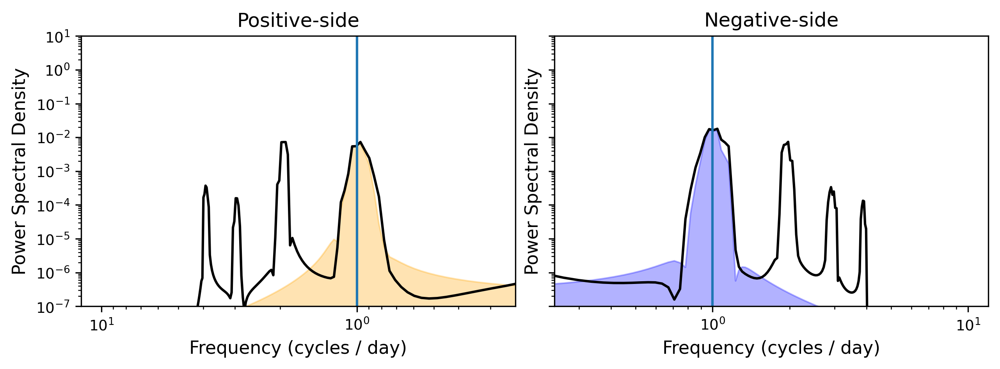

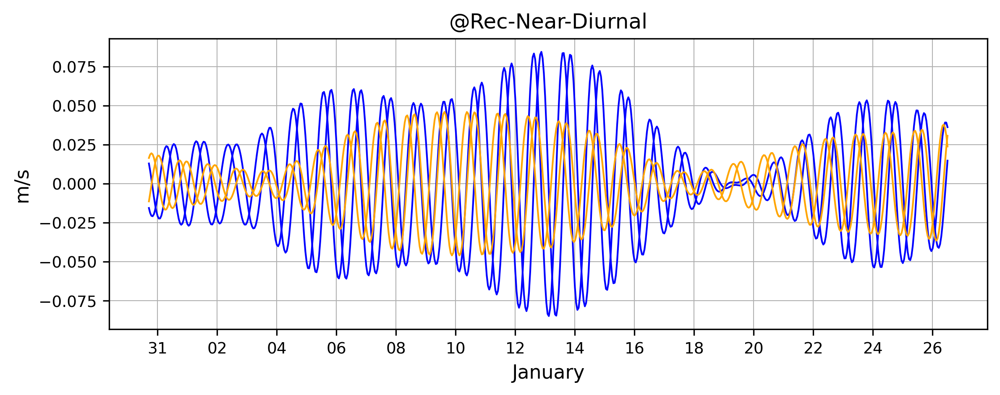

In [49]:
import clouddrift.wavelet as wt
from scipy import signal, ndimage

dt = 1/24
P = 2
x = u_re1_tide[:,20]/1000
y = v_re1_tide[:,20]/1000
cv = x + 1j * y
spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
S = np.ravel(spec.spec)
f = np.ravel(spec.freq)

gamma = 3
beta = 30
period = 24/24 #period you're interested in. Here it's the M2 tide,
omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

_, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
psif = psif[0,0]
cvo_neg, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
cvo_pos, _ = np.conj(wt.morse_wavelet_transform(np.conj(cv),gamma,beta,[omega],complex=True,boundary="mirror"))

spec = MTSpec(cvo_neg, nw=P, dt=dt, iadapt=1, nfft=len(cv))
So_neg = np.ravel(spec.spec)

spec = MTSpec(cvo_pos, nw=P, dt=dt, iadapt=1, nfft=len(cv))
So_pos = np.ravel(spec.spec)

fig, ax = plt.subplots(1, 2, figsize=(10, 3), sharey=True, gridspec_kw={"wspace": 0.09})

ax[0].loglog(-f[f<0],S[f<0], color = 'k')  #plot pos
ax[0].fill_between(-f[f<0],So_pos[f<0], color='orange', alpha=0.3)

ax[0].set_xlabel("Frequency (cycles / day)")
ax[0].set_ylabel("Power Spectral Density")
ax[0].set_xlim(np.max(f)/50, np.max(f))
ax[0].set_ylim(10e-8, 10e0)
ax[0].invert_xaxis()
ax[0].set_title("Positive-side")
ax[0].axvline(1)
plt.grid()

ax[1].loglog(f[f>0],S[f>0], color = 'k')#plot positive side
ax[1].fill_between(f[f > 0], So_neg[f > 0], color='blue', alpha=0.3)

ax[1].set_xlabel("Frequency (cycles / day)")
ax[1].set_ylabel("Power Spectral Density")
ax[1].set_xlim(np.max(f)/50, np.max(f))
ax[1].set_ylim(10e-8, 10e0)
ax[1].set_title("Negative-side")
ax[1].axvline(1)
plt.grid()
#------------

plt.figure(figsize=(9,3))
plt.plot(t1,cvo_neg.real, color = 'blue', linewidth = 1)
plt.plot(t1,cvo_neg.imag, color = 'blue', linewidth = 1)
plt.plot(t1,cvo_pos.real, color = 'orange', linewidth = 1)
plt.plot(t1,cvo_pos.imag, color = 'orange', linewidth = 1)
plt.grid()
plt.ylabel('m/s')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel(dataA['time'][50].strftime('%B'))
plt.title('@Rec-Near-Diurnal')


In [50]:
#

In [51]:
u_re1_24neg = np.full((644, 22), np.nan)
v_re1_24neg = np.full((644, 22), np.nan)

u_re1_24pos = np.full((644, 22), np.nan)
v_re1_24pos = np.full((644, 22), np.nan)

for i in range(0,22):

    dt = 1/24
    P = 2
    x = u_re1_tide[:,i]/1000
    y = v_re1_tide[:,i]/1000
    cv = x + 1j * y
    spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    S = np.ravel(spec.spec)
    f = np.ravel(spec.freq)

    gamma = 3
    beta = 30
    period = 23/24 #period you're interested in. Here it's the M2 tide,
    omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

    _, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
    psif = psif[0,0]
    cvo_neg, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
    cvo_pos, _ = np.conj(wt.morse_wavelet_transform(np.conj(cv),gamma,beta,[omega],complex=True,boundary="mirror"))
    
    u_re1_24neg[:,i] = cvo_neg.real
    v_re1_24neg[:,i] = cvo_neg.imag

    u_re1_24pos[:,i] = cvo_pos.real
    v_re1_24pos[:,i] = cvo_pos.imag

In [52]:
sp_re1_24neg = np.sqrt(u_re1_24neg**2 + v_re1_24neg**2) 
sp_re1_24pos = np.sqrt(u_re1_24pos**2 + v_re1_24pos**2) 

In [53]:
def progressive_vector(u_mm_s, v_mm_s, time_index, break_on_gaps=True):
    """
    Compute progressive displacements (x_km, y_km) from u, v (mm/s) over time.

    Parameters
    ----------
    u_mm_s, v_mm_s : array-like or pandas Series
        Eastward (u) and northward (v) velocity components in mm/s.
    time_index : pandas.DatetimeIndex (or array convertible to it)
        Timestamps corresponding to u, v samples.
    break_on_gaps : bool
        If True, returns a mask to break the plot at data gaps (>1.5 * median dt).

    Returns
    -------
    x_km, y_km : np.ndarray
        Cumulative displacements in kilometers.
    segments_mask : np.ndarray of bool
        True where segment is continuous (useful to break the line on gaps).
    """
    # Ensure pandas objects
    t = pd.DatetimeIndex(time_index)
    u = pd.Series(u_mm_s, index=t, dtype='float64')
    v = pd.Series(v_mm_s, index=t, dtype='float64')

    # Align & remove rows where either component is NaN
    uv = pd.concat([u.rename('u'), v.rename('v')], axis=1)
    valid = uv.notna().all(axis=1)
    uv = uv[valid]
    t = uv.index

    if len(t) < 2:
        raise ValueError("Not enough valid samples after removing NaNs.")

    # Irregular sampling supported: compute dt (seconds) between samples
    dt_s = np.diff(t.view('int64')) / 1e9  # ns -> s

    # Optionally detect big gaps to break the line later
    if break_on_gaps:
        med = np.median(dt_s)
        gap_thresh = 1.5 * med if np.isfinite(med) and med > 0 else np.inf
        # segments_mask length must equal number of steps; prepend True for first point
        seg_ok = np.concatenate([[True], dt_s <= gap_thresh])
    else:
        seg_ok = np.ones(len(t), dtype=bool)

    # Convert mm/s -> m/s
    u_ms = uv['u'].to_numpy() / 1000.0
    v_ms = uv['v'].to_numpy() / 1000.0

    # Displacements per step (meters) using dt between consecutive samples.
    # Pad dt to align with samples (first step assumed same dt as first diff for simplicity).
    dt_aligned = np.concatenate([[dt_s[0]], dt_s])

    dx_m = u_ms * dt_aligned
    dy_m = v_ms * dt_aligned

    # Cumulative sum -> position (meters), then to km
    x_km = np.cumsum(dx_m) / 1000.0
    y_km = np.cumsum(dy_m) / 1000.0

    return x_km, y_km, seg_ok, t

In [ ]:
#

In [71]:
def progressive_vector(u_mm_s, v_mm_s, time_index, break_on_gaps=True):
    """
    Compute progressive displacements (x_km, y_km) from u, v (mm/s) over time.

    Parameters
    ----------
    u_mm_s, v_mm_s : array-like or pandas Series
        Eastward (u) and northward (v) velocity components in mm/s.
    time_index : pandas.DatetimeIndex (or array convertible to it)
        Timestamps corresponding to u, v samples.
    break_on_gaps : bool
        If True, returns a mask to break the plot at data gaps (>1.5 * median dt).

    Returns
    -------
    x_km, y_km : np.ndarray
        Cumulative displacements in kilometers.
    segments_mask : np.ndarray of bool
        True where segment is continuous (useful to break the line on gaps).
    """
    # Ensure pandas objects
    t = pd.DatetimeIndex(time_index)
    u = pd.Series(u_mm_s, index=t, dtype='float64')
    v = pd.Series(v_mm_s, index=t, dtype='float64')

    # Align & remove rows where either component is NaN
    uv = pd.concat([u.rename('u'), v.rename('v')], axis=1)
    valid = uv.notna().all(axis=1)
    uv = uv[valid]
    t = uv.index

    if len(t) < 2:
        raise ValueError("Not enough valid samples after removing NaNs.")

    # Irregular sampling supported: compute dt (seconds) between samples
    dt_s = np.diff(t.view('int64')) / 1e9  # ns -> s

    # Optionally detect big gaps to break the line later
    if break_on_gaps:
        med = np.median(dt_s)
        gap_thresh = 1.5 * med if np.isfinite(med) and med > 0 else np.inf
        # segments_mask length must equal number of steps; prepend True for first point
        seg_ok = np.concatenate([[True], dt_s <= gap_thresh])
    else:
        seg_ok = np.ones(len(t), dtype=bool)

    # Convert mm/s -> m/s
    u_ms = uv['u'].to_numpy() / 1000.0
    v_ms = uv['v'].to_numpy() / 1000.0

    # Displacements per step (meters) using dt between consecutive samples.
    # Pad dt to align with samples (first step assumed same dt as first diff for simplicity).
    dt_aligned = np.concatenate([[dt_s[0]], dt_s])

    dx_m = u_ms * dt_aligned
    dy_m = v_ms * dt_aligned

    # Cumulative sum -> position (meters), then to km
    x_km = np.cumsum(dx_m) / 1000.0
    y_km = np.cumsum(dy_m) / 1000.0

    return x_km, y_km, seg_ok, t

In [33]:
#

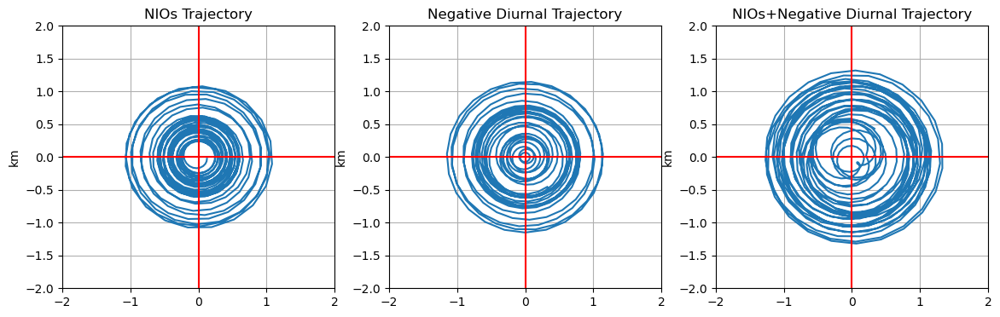

In [55]:
plt.figure(figsize=(14,4))
plt.subplot(1,3,1)
x_km1, y_km1, seg_ok, t_valid = progressive_vector(u_re1_nios[:,20]*1000,v_re1_nios[:,20]*1000, t1)
plt.plot(x_km1-np.nanmean(x_km1),y_km1-np.nanmean(y_km1))
plt.xlim([-2,2]), plt.ylim([-2,2])
plt.title('NIOs Trajectory')
plt.axvline(0, color = 'r'), plt.axhline(0, color = 'r')
plt.ylabel('km'),plt.ylabel('km')
plt.grid()
plt.subplot(1,3,2)
x_km2, y_km2, seg_ok, t_valid = progressive_vector(u_re1_24neg[:,20]*1000,v_re1_24neg[:,20]*1000, t1)
plt.plot(x_km2-np.nanmean(x_km2),y_km2-np.nanmean(y_km2))
plt.xlim([-2,2]), plt.ylim([-2,2])
plt.title('Negative Diurnal Trajectory')
plt.axvline(0, color = 'r'), plt.axhline(0, color = 'r')
plt.ylabel('km'),plt.ylabel('km')
plt.grid()
plt.subplot(1,3,3)
plt.plot(x_km1+x_km2 - np.nanmean(x_km1+x_km2),y_km1+y_km2 - np.nanmean(y_km1+y_km2))
plt.xlim([-2,2]), plt.ylim([-2,2])
plt.title('NIOs+Negative Diurnal Trajectory')
plt.axvline(0, color = 'r'), plt.axhline(0, color = 'r')
plt.ylabel('km'),plt.ylabel('km')
plt.grid()

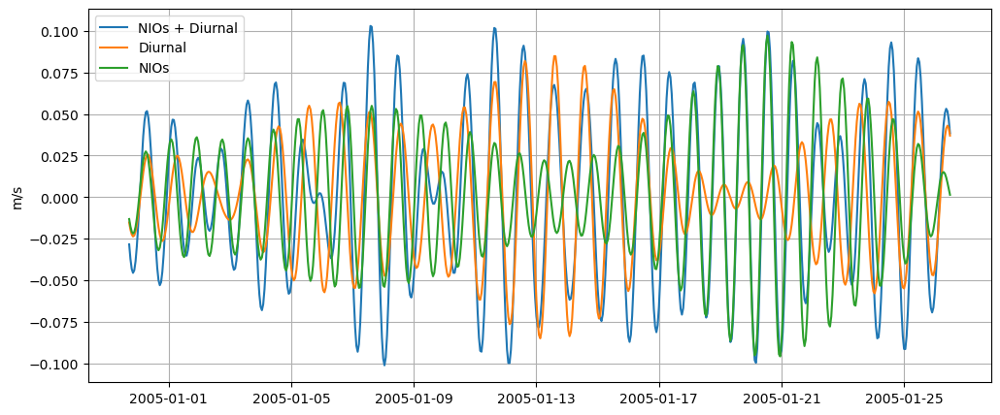

In [70]:
plt.figure(figsize=(12,5))
plt.plot(t1,u_re1_24neg[:,i]+u_re1_nios[:,i], label = 'NIOs + Diurnal')
plt.plot(t1,u_re1_24neg[:,i], label = 'Diurnal')
plt.plot(t1,u_re1_nios[:,i], label = 'NIOs')
plt.ylabel('m/s')
plt.legend()
plt.grid()

NameError: name 'progressive_vector' is not defined

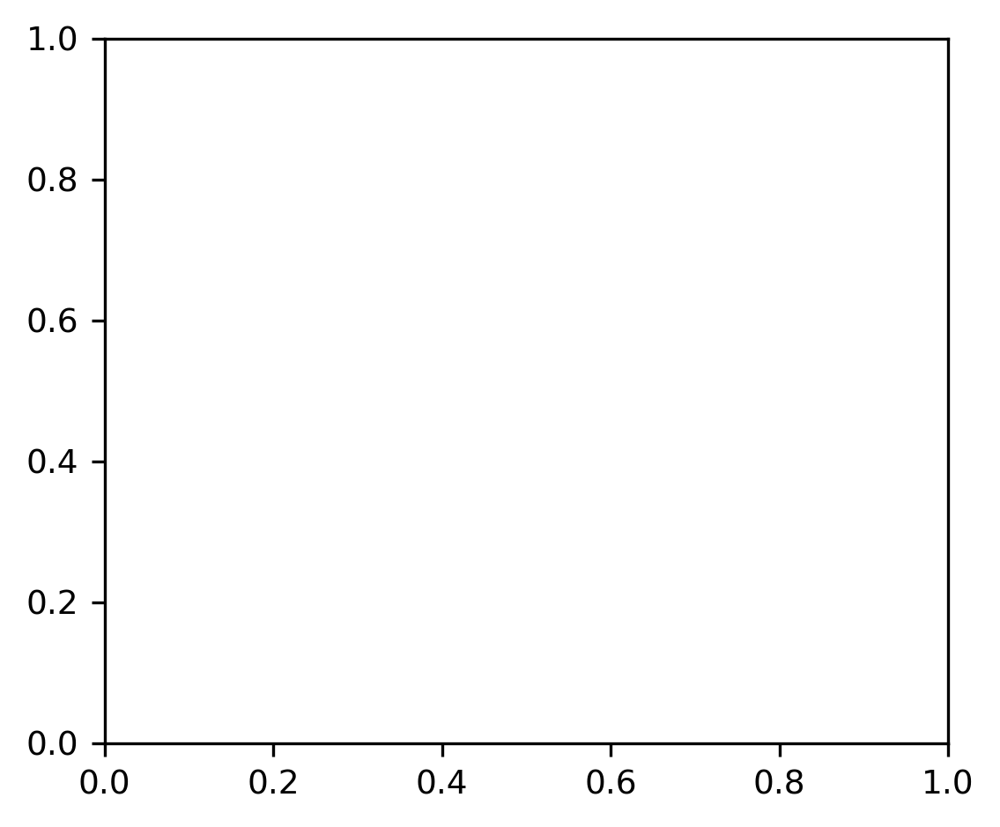

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Create a figure with a GridSpec layout:
# Row 0 has 3 subplots for trajectories (1x3)
# Row 1 spans across all columns for the time series comparison
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])

# ---------------------------------------------------------
# Subplot (a): NIOs Trajectory (Row 0, Col 0)
# ---------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])
x_km1, y_km1, seg_ok, t_valid = progressive_vector(
    u_re1_nios[:, 20] * 1000, v_re1_nios[:, 20] * 1000, t1
)
ax1.plot(
    x_km1 - np.nanmean(x_km1), y_km1 - np.nanmean(y_km1), color="tab:blue"
)
ax1.set_xlim([-2, 2])
ax1.set_ylim([-2, 2])
ax1.set_title("(a) NIOs Trajectory")
ax1.axvline(0, color="r", linestyle="--", alpha=0.7)
ax1.axhline(0, color="r", linestyle="--", alpha=0.7)
ax1.set_ylabel("km")
ax1.set_xlabel("km")
ax1.grid(True)

# ---------------------------------------------------------
# Subplot (b): Negative Diurnal Trajectory (Row 0, Col 1)
# ---------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])
x_km2, y_km2, seg_ok, t_valid = progressive_vector(
    u_re1_24neg[:, 20] * 1000, v_re1_24neg[:, 20] * 1000, t1
)
ax2.plot(
    x_km2 - np.nanmean(x_km2), y_km2 - np.nanmean(y_km2), color="tab:orange"
)
ax2.set_xlim([-2, 2])
ax2.set_ylim([-2, 2])
ax2.set_title("(b) Negative Diurnal Trajectory")
ax2.axvline(0, color="r", linestyle="--", alpha=0.7)
ax2.axhline(0, color="r", linestyle="--", alpha=0.7)
ax2.set_ylabel("km")
ax2.set_xlabel("km")
ax2.grid(True)

# ---------------------------------------------------------
# Subplot (c): NIOs + Negative Diurnal Trajectory (Row 0, Col 2)
# ---------------------------------------------------------
ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(
    (x_km1 + x_km2) - np.nanmean(x_km1 + x_km2),
    (y_km1 + y_km2) - np.nanmean(y_km1 + y_km2),
    color="tab:green",
)
ax3.set_xlim([-2, 2])
ax3.set_ylim([-2, 2])
ax3.set_title("(c) NIOs + Negative Diurnal")
ax3.axvline(0, color="r", linestyle="--", alpha=0.7)
ax3.axhline(0, color="r", linestyle="--", alpha=0.7)
ax3.set_ylabel("km")
ax3.set_xlabel("km")
ax3.grid(True)

# ---------------------------------------------------------
# Subplot (d): Time Series Comparison (Row 1, spanning all columns)
# ---------------------------------------------------------
ax4 = fig.add_subplot(gs[1, :])
# Note: using variable index `i` as specified in your snippet
ax4.plot(
    t1,
    u_re1_24neg[:, i] + u_re1_nios[:, i],
    label="NIOs + Diurnal",
    color="tab:purple",
)
ax4.plot(t1, u_re1_24neg[:, i], label="Diurnal", color="tab:orange")
ax4.plot(t1, u_re1_nios[:, i], label="NIOs", color="tab:blue")
ax4.set_ylabel("m/s")
ax4.set_xlabel("Time")
ax4.set_title(
    "(d) Comparison of Zonal Velocity Components (NIOs and Diurnal)"
)
ax4.legend(loc="upper right")
ax4.grid(True)

plt.tight_layout()
plt.show()

/tmp/ipykernel_51568/2334936981.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


(np.float64(-0.10542524896653795),
 np.float64(0.10683851398435927),
 np.float64(-0.10621180737566732),
 np.float64(0.10662075748491504))

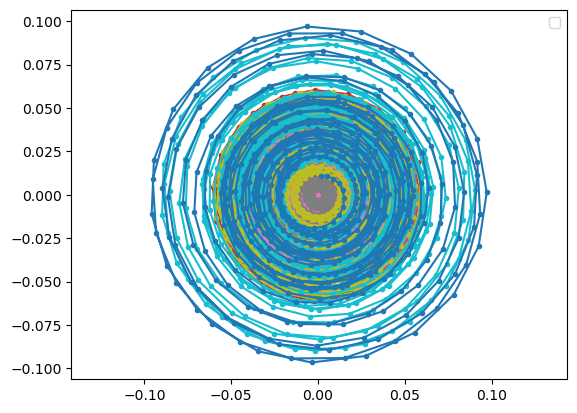

In [68]:
for i in range(0,21):
    plt.plot(u_re1_nios[:,i] - np.nanmean(u_re1_nios[:,i]), v_re1_nios[:,i] - np.nanmean(v_re1_nios[:,i]), marker = '.')

plt.axis('equal')

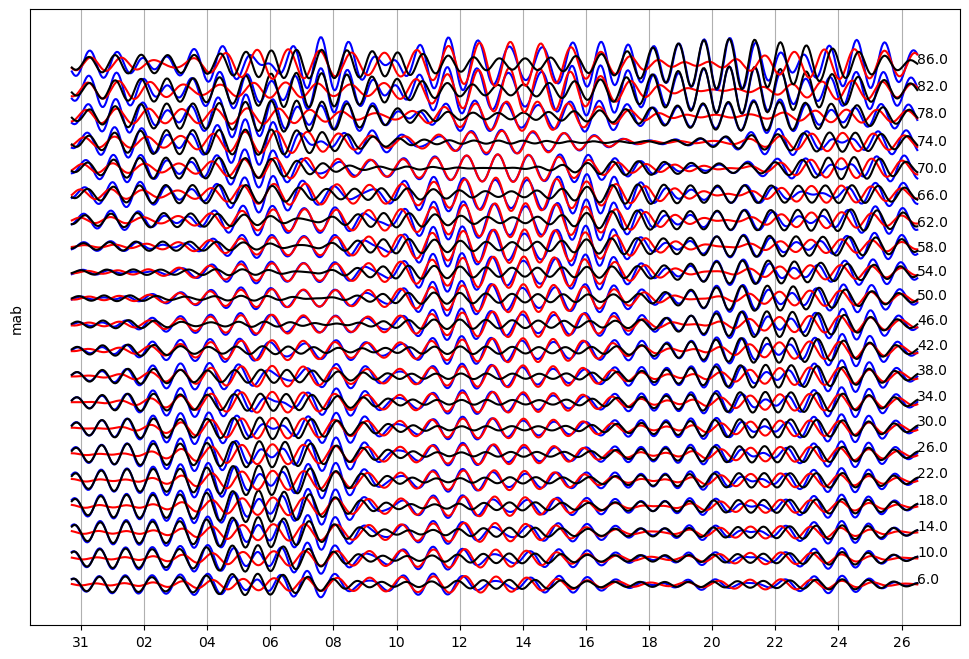

In [79]:
plt.figure(figsize=(12,8))
for i in range(0,21):
    plt.plot(t1,(u_re1_24neg[:,i]+u_re1_nios[:,i])+0.1*i, label = 'NIOs + Diurnal', color = 'b')
    plt.plot(t1,u_re1_24neg[:,i]+0.1*i, label = 'Diurnal', color = 'r')
    plt.plot(t1,u_re1_nios[:,i]+0.1*i, label = 'NIOs', color = 'k' )
    plt.text(t1[-1],u_re1_nios[-1,i]+0.1*i, np.round(dataA['depth'][i]))

plt.ylabel('mab')
plt.yticks([])
plt.grid()
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))

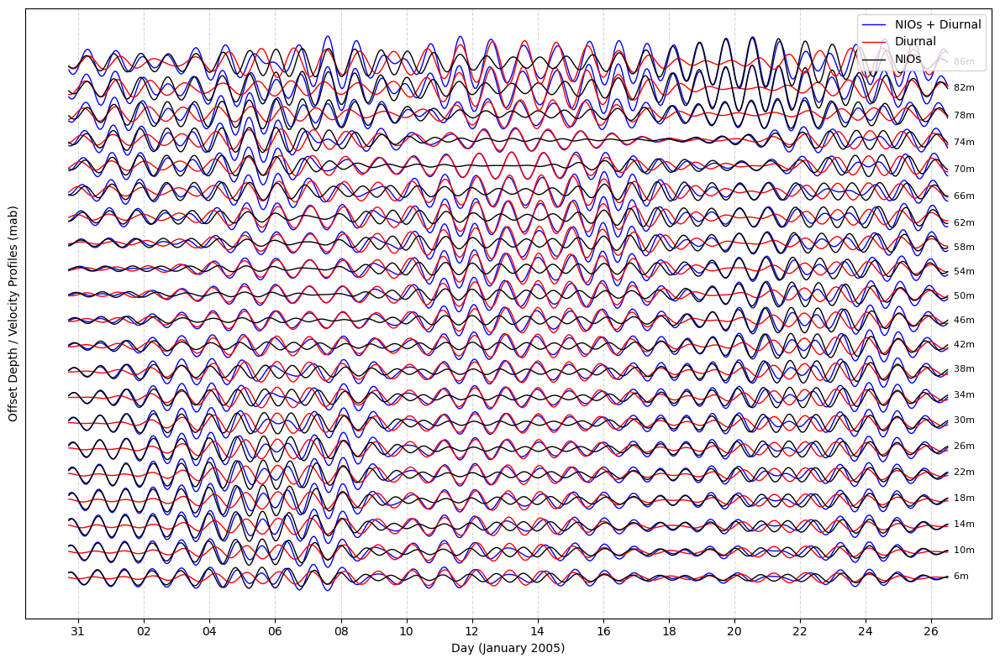

In [81]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

plt.figure(figsize=(12, 8))

# Loop through depths and plot without adding duplicate labels to the legend
for i in range(0, 21):
  # Only add the label for the very first iteration so it appears only once in the legend
  label_sum = "NIOs + Diurnal" if i == 0 else ""
  label_diurnal = "Diurnal" if i == 0 else ""
  label_nios = "NIOs" if i == 0 else ""

  plt.plot(
      t1,
      (u_re1_24neg[:, i] + u_re1_nios[:, i]) + 0.1 * i,
      label=label_sum,
      color="b",
      linewidth=1,
  )
  plt.plot(
      t1,
      u_re1_24neg[:, i] + 0.1 * i,
      label=label_diurnal,
      color="r",
      linewidth=1,
  )
  plt.plot(
      t1,
      u_re1_nios[:, i] + 0.1 * i,
      label=label_nios,
      color="k",
      linewidth=1,
  )

  # Text label for depth at the end of the lines
  depth_label = f"{np.round(dataA['depth'][i]):.0f}m"
  plt.text(
      t1[-1],
      u_re1_nios[-1, i] + 0.1 * i,
      f"  {depth_label}",
      verticalalignment="center",
      fontsize=8,
  )

plt.ylabel("Offset Depth / Velocity Profiles (mab)")
plt.xlabel("Day (January 2005)")
plt.yticks([])
plt.grid(True, linestyle="--", alpha=0.5)

# Date formatting
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%d"))

# Place legend cleanly outside or in a clear spot
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

(np.float64(-0.00438597411696057),
 np.float64(0.08298297353669183),
 np.float64(-0.003805970127873298),
 np.float64(0.06690893281935568))

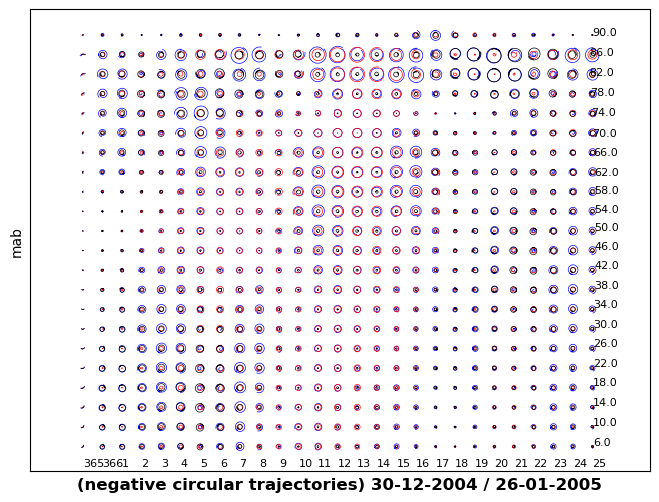

In [108]:
plt.figure(figsize=(8,6))
doy = t1.dayofyear
idx = pd.unique(doy)

for g in range(0,22):
    for i in range(0, len(idx)-1):
        z = np.where(doy == idx[i])[0]
        if np.isnan(u_re1_diurnal[z,g]).sum() < 1:
            
            x = u_re1_24neg[z,g]+u_re1_nios[z,g]
            y = v_re1_24neg[z,g]+v_re1_nios[z,g]
            x_km1, y_km1, seg_ok, t_valid = progressive_vector(x,y,t1[z])
            x_km2, y_km2, seg_ok, t_valid = progressive_vector(u_re1_24neg[z,g], v_re1_24neg[z,g], t1[z])
            x_km3, y_km3, seg_ok, t_valid = progressive_vector(u_re1_nios[z,g], v_re1_nios[z,g], t1[z])
            
            plt.plot(x_km1-np.nanmean(x_km1)+0.003*i,y_km1-np.nanmean(y_km1)+0.003*g, linewidth = 0.5, color = 'b')
            plt.plot(x_km2-np.nanmean(x_km2)+0.003*i,y_km2-np.nanmean(y_km2)+0.003*g, linewidth = 0.5, color = 'r')
            plt.plot(x_km3-np.nanmean(x_km3)+0.003*i,y_km3-np.nanmean(y_km3)+0.003*g, linewidth = 0.5, color = 'k')

            if g == 0:
              plt.text(x_km[0]+0.003*i,y_km[0]-0.003,idx[i], fontsize = 8)


for g in range(0,22):
    for i in range(26, 27):
        z = np.where(doy == idx[i])[0]
        if np.isnan(u_re1_diurnal[z,g]).sum() < 1:
            x_km, y_km, seg_ok, t_valid = progressive_vector(u_re1_nios[z,g], v_re1_nios[z,g], t1[z])
            plt.text(x_km[-1]+0.003*i,y_km[-1]+0.003*g, np.round(dataA['depth'][g]), fontsize = 8)

plt.gca().set_aspect('equal', adjustable='box')  # equal aspect, keep current limits
plt.axis('tight')
plt.xlabel(f'(negative circular trajectories) {t1[0].strftime("%d-%m-%Y")} / {t1[-1].strftime("%d-%m-%Y")}', fontsize=12, weight='bold')
plt.ylabel('mab')
plt.xticks([])   # no x ticks
plt.yticks([])   # no y ticks
plt.grid()
plt.axis('equal')


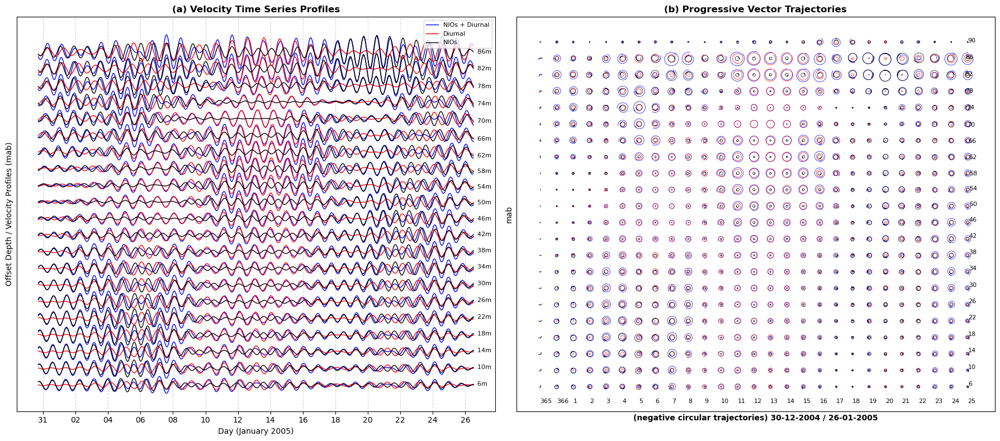

In [109]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# Create a figure with a 1x2 side-by-side subplot layout
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# -------------------------------------------------------------------------
# Left Subplot: Offset Velocity Time Series Profiles
# -------------------------------------------------------------------------
ax_left = axes[0]
for i in range(0, 21):
  label_sum = "NIOs + Diurnal" if i == 0 else ""
  label_diurnal = "Diurnal" if i == 0 else ""
  label_nios = "NIOs" if i == 0 else ""

  ax_left.plot(
      t1,
      (u_re1_24neg[:, i] + u_re1_nios[:, i]) + 0.1 * i,
      label=label_sum,
      color="b",
      linewidth=1,
  )
  ax_left.plot(
      t1,
      u_re1_24neg[:, i] + 0.1 * i,
      label=label_diurnal,
      color="r",
      linewidth=1,
  )
  ax_left.plot(
      t1,
      u_re1_nios[:, i] + 0.1 * i,
      label=label_nios,
      color="k",
      linewidth=1,
  )

  depth_label = f"{np.round(dataA['depth'][i]):.0f}m"
  ax_left.text(
      t1[-1],
      u_re1_nios[-1, i] + 0.1 * i,
      f"  {depth_label}",
      verticalalignment="center",
      fontsize=8,
  )

ax_left.set_ylabel("Offset Depth / Velocity Profiles (mab)")
ax_left.set_xlabel("Day (January 2005)")
ax_left.set_yticks([])
ax_left.grid(True, linestyle="--", alpha=0.5)
ax_left.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax_left.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
ax_left.legend(loc="upper right", frameon=True, fontsize=8)
ax_left.set_title("(a) Velocity Time Series Profiles", fontweight="bold")

# -------------------------------------------------------------------------
# Right Subplot: Progressive Vector / Circular Trajectories
# -------------------------------------------------------------------------
ax_right = axes[1]
doy = t1.dayofyear
idx = pd.unique(doy)

for g in range(0, 22):
  for i in range(0, len(idx) - 1):
    z = np.where(doy == idx[i])[0]
    if np.isnan(u_re1_diurnal[z, g]).sum() < 1:
      x = u_re1_24neg[z, g] + u_re1_nios[z, g]
      y = v_re1_24neg[z, g] + v_re1_nios[z, g]
      x_km1, y_km1, _, _ = progressive_vector(x, y, t1[z])
      x_km2, y_km2, _, _ = progressive_vector(
          u_re1_24neg[z, g], v_re1_24neg[z, g], t1[z]
      )
      x_km3, y_km3, _, _ = progressive_vector(
          u_re1_nios[z, g], v_re1_nios[z, g], t1[z]
      )

      ax_right.plot(
          x_km1 - np.nanmean(x_km1) + 0.003 * i,
          y_km1 - np.nanmean(y_km1) + 0.003 * g,
          linewidth=0.5,
          color="b",
      )
      ax_right.plot(
          x_km2 - np.nanmean(x_km2) + 0.003 * i,
          y_km2 - np.nanmean(y_km2) + 0.003 * g,
          linewidth=0.5,
          color="r",
      )
      ax_right.plot(
          x_km3 - np.nanmean(x_km3) + 0.003 * i,
          y_km3 - np.nanmean(y_km3) + 0.003 * g,
          linewidth=0.5,
          color="k",
      )

      if g == 0 and "x_km" in locals():
        ax_right.text(
            x_km[0] + 0.003 * i, y_km[0] - 0.003, idx[i], fontsize=8
        )

for g in range(0, 22):
  for i in range(26, 27):
    z = np.where(doy == idx[i])[0]
    if np.isnan(u_re1_diurnal[z, g]).sum() < 1:
      x_km, y_km, _, _ = progressive_vector(
          u_re1_nios[z, g], v_re1_nios[z, g], t1[z]
      )
      ax_right.text(
          x_km[-1] + 0.003 * i,
          y_km[-1] + 0.003 * g,
          str(int(np.round(dataA["depth"][g]))),
          fontsize=8,
      )

ax_right.set_aspect("equal", adjustable="box")
ax_right.axis("tight")
ax_right.set_xlabel(
    f"(negative circular trajectories) {t1[0].strftime('%d-%m-%Y')} / {t1[-1].strftime('%d-%m-%Y')}",
    fontsize=10,
    weight="bold",
)
ax_right.set_ylabel("mab")
ax_right.set_xticks([])
ax_right.set_yticks([])
ax_right.grid(True)
ax_right.axis("equal")
ax_right.set_title("(b) Progressive Vector Trajectories", fontweight="bold")

plt.tight_layout()
plt.show()